# EEG-informed fNIRS modeling in gradCPT_NN24: overview of the work so far

*Status as of 2026-11-03 (git `5738eb8`). This notebook pulls together the whole repo history (280 commits, 2025-10-16 → 2026-11-03), the [modeling README](README.md) and the five `summary_*.ipynb` write-ups, plus the new Bayesian work in [Bayesian model/](Bayesian%20model/). It refits nothing. §5 computes its comparisons from saved betas; the other code cells only display figures that are already saved; run the setup cell in §2 first.*

**Contents**
1. Bottom line
2. Data, subjects and EEG preprocessing (context)
3. Timeline
4. Modeling stages: question → what was done → result, with the main figures under each stage
5. mnt-correct HRF across four model designs (GK, EEG-informed GK, continuous EEG within trials, continuous EEG over the entire run)
6. Conclusion: what modeling the HRF with EEG and fNIRS has shown
7. Methodological lessons (things that went wrong and how they were fixed)
8. Open items and suggested next steps
9. Where to find things

## 1. Bottom line

**Question.** Does scalp EEG (mainly Cz) explain the fNIRS HbO signal during gradCPT? If so, what does the EEG→HbO "HRF" look like across parcels and subjects? Which estimator gives a reliable HRF?

**Answers so far**

| | Finding | Evidence |
|---|---|---|
| EEG → HbO effect size | **Tiny.** In-sample R² < 2% (continuous Cz EEG) and < 0.3% (mnt-correct design) of the whitened variance | `summary_cmp_fixAR-IRLS_AR-iRRR_single-subj` Part B |
| Generalization | **None detected.** Trained on run 1 and tested on runs 2–3, test R² is ≈ 0 or negative for every model and design. The best held-out iRRR rank is 0 for most subjects: 4/6 (Cz EEG), 3/6 (mnt-correct), 14/20 (Gaussian-kernel, N = 20) | single-subj Part A; city_mnt §14g |
| CV-selected λ₁ | Shrinks 3 of 6 subjects to rank 0. Where rank > 0, held-out PMSE drops by only 0.03–0.15% | `summary_Hp_fixAR-IRLS_iRRR_AR` |
| Noise model (AR-IRLS vs fixAR-IRLS) | **Barely changes HRF shape.** Median per-parcel r = 0.87 (N = 20, event design) and 0.91 (within-trial EEG design). fixAR-IRLS amplitudes are ~19% smaller, with similar SEs | `summary_cmp_AR-IRLS_fixAR-IRLS_AR-iRRR`; city_mnt §5 |
| Low-rank AR-iRRR | A **shrunken, smoother** version of the IRLS fits: r ≈ 0.4–0.77 against IRLS, ~4× smaller at rank 2. Its components differ across subjects, so there is **no single shared HRF shape** | same |
| Event-locked mnt-correct HRF (no EEG) | ContA network-mean HRF: peak at ~4.5 s, dip at ~8 s. Prefrontal ContA/DefaultA/SalVentAttnB parcels are the most significant. The shape is robust to pipeline choices (GK-net vs GK-cmp r ≈ 0.91–0.98) | `summary_cmp_AR-IRLS…`; city_mnt §12, §15 |
| EEG-weighted vs event-based design | **The design, not the pipeline, sets the HRF shape.** Same design, different pipeline: r ≈ 0.87–0.98. Same pipeline, EEG-weighted vs Gaussian-kernel: r ≈ 0.1–0.3 | city_mnt §15a |
| EEG-informed event HRF (kernels scaled by single-trial Cz ERP area) | **Identical to the plain event HRF** (r = 0.99, RMS ratio 1.01). The ERP-area term is at chance (median 5% of parcels with p < 0.05), and its regressor correlates 0.70–0.92 with the plain kernels | §5 |
| Bayesian joint HRF + AR model | Recovers a planted HRF in simulation. On one real parcel (sub-723, run 1), the 95% credible band of the HRF contains 0 at almost every lag | §4, Stage 9 |

**One-sentence summary.** An event-locked mnt-correct HbO response exists and is estimated consistently. Weighting it by single-trial Cz EEG adds no detectable, generalizable information, and the estimator choice affects mostly amplitude, not shape.

## 2. Data, subjects and EEG preprocessing (context)

**Task and signals.** gradCPT (city = frequent go trials, mountain = rare no-go trials), recorded with simultaneous EEG, fNIRS (with image reconstruction to cortical parcels, Adot v26) and eye tracking/pupil. The modeled trial types are **mnt-correct** (correct withhold, `response_code == 0`) and **mnt-incorrect**.

**EEG preprocessing** ([../preproc_pipe/](../preproc_pipe/), Oct 2025 – Jul 2026)
- [eeg_preprocess_pipeline.py](../preproc_pipe/eeg_preprocess_pipeline.py) / `utils.eeg_preproc_subj_level`:
  - filtering;
  - trigger parsing (button-press polarity detection; BIDS-aligned `events.tsv`);
  - bad-channel removal (one-sided variance check plus large-amplitude detection);
  - ASR;
  - ICA with EOG-component removal;
  - mastoid re-reference. Common average was tried and removed the P3.
- ERP/ERSP analyses at the single-subject and group level ([xSubj_analysis_ERP_ERSP.py](../preproc_pipe/xSubj_analysis_ERP_ERSP.py)), split by in/out-of-the-zone (VTC), by RT, and by pupil. Manual IC selection with ASR 20 and 31 ICs gave no clear P300 (commit `2c752e6`).

**fNIRS inputs to the models**
- Image-space parcel HbO.
- Sensitivity mask `log10 Σ_ch A > −2`, which leaves 417–429 parcels, depending on the script.
- Per run: highpass 0.01–0.02 Hz, then truncation to the trial window, then OLS Legendre drift, then OLS GSR. Runs are concatenated as gradcpt1, 2, 3.

**Subjects**
- **Continuous-EEG work: N = 6** (670, 695, 721, 723, 726, 730). Inclusion: gradCPT fNIRS, ≥ 500 clean EEG epochs, not in `excluded_subj`, and Cz kept in every run.
- **Event-based Gaussian-kernel comparison: N = 20.** It does not need EEG.
- The network-based scripts skip sub-670: in the shared `Y_all`, runs gradcpt1 and gradcpt2 hold duplicated fNIRS data.

In [69]:
# Figure helper: displays saved figures only (nothing is refit). Missing files are reported, not raised.
import os
from IPython.display import Image, Markdown, display

D = '/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg'
G = os.path.join(D, 'HRF_surf', 'group')
MODELING = '/projectnb/nphfnirs/s/datasets/gradCPT_NN24/code/eeg/modeling'
BAYES_V1 = os.path.join(D, 'HRF_surf', 'sub-723', 'Bayes-HRF-AR_mnt-correct_gauss_1-stage_gradcpt1_Hp')
BAYES_V2 = BAYES_V1 + '_noSmooth'

def show(items, width=900):
    for caption, path in items:
        display(Markdown(f'**{caption}**  \n<sub>`{path}`</sub>'))
        if os.path.exists(path):
            display(Image(filename=path, width=width))
        else:
            display(Markdown('_missing_'))

**Cz ERP, city vs mountain trials, across subjects. Context for the EEG regressors.**  
<sub>`/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/xSubj_results/ERP_city_vs_mnt/xSubj_ERP_city_vs_mnt_cz.png`</sub>

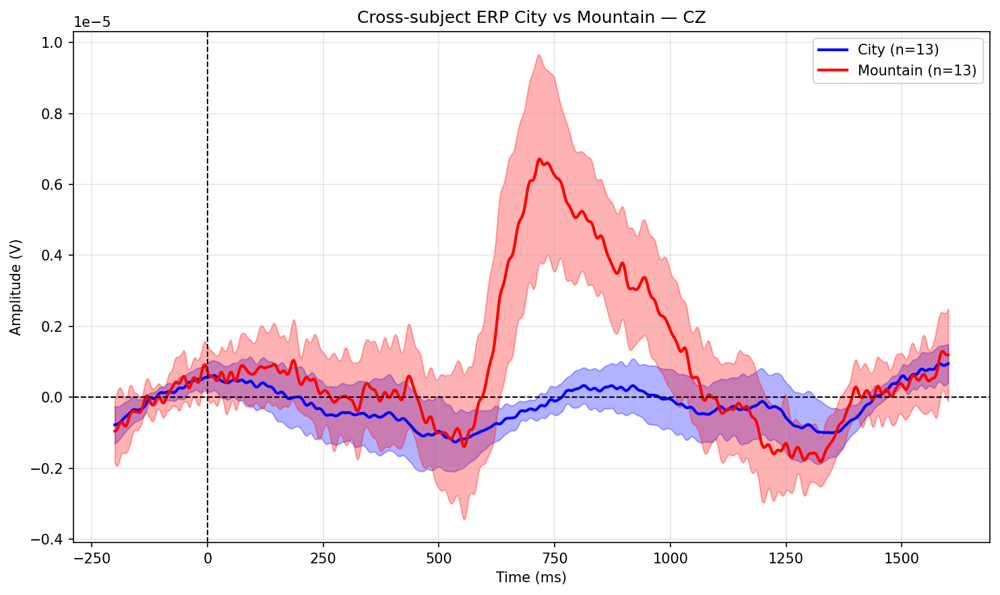

In [70]:
show([
    ('Cz ERP, city vs mountain trials, across subjects. Context for the EEG regressors.',
     os.path.join(D, 'xSubj_results/ERP_city_vs_mnt/xSubj_ERP_city_vs_mnt_cz.png')),
])

## 3. Timeline

| Period | Phase | Representative commits |
|---|---|---|
| Oct – Dec 2025 | EEG preprocessing pipeline, ERP/ERSP, VTC checks, downsampling EEG to fNIRS | `494d7a4`, `0f60021`, `070b9d4` |
| Jan – Mar 2026 | **EEG-informed event GLM** (ERP-area / alpha modulators), full vs reduced models, F-tests; own AR-IRLS implementation | `57cffe1`, `9554602`, `a63c87f`, `9e6a176` |
| Apr – Jun 2026 | Network-averaged models; pupil/VTC side track (van den Brink 2016 reproduction); preprocessing rewrite | `4749567`, `abc4e59`, `5d29c0d` |
| Jul 2026 | Matched `my_ar_irls_GLM` to Cedalion; OLS/drift checks; move to image space | `4c8bd13`, `bdb43fd` |
| Aug 2026 | **Continuous-EEG GLM** (Cz, delayed, B-splines); GSR; band-power regressors; correct image-space GLM code | `13d6256`, `b6c8e0f`, `d9578aa`, `6db6bf3` |
| early Sep 2026 | **3-stage fitting** (drift → GSR → AR-IRLS), sensitivity mask, F-tests, VTC regressor | `11f3a4b`, `786951f`, `153812a` |
| mid–late Sep 2026 | HRF structure (SVD/ICA, cross-subject joint SVD) → **iRRR** | `85e4956`, `87736dc`, `3375126` |
| early Oct 2026 | AR whitening breaks iRRR → **spectral whitening → fixAR-IRLS / AR-iRRR**; Y scaling; λ₁ by CV | `33bb9bb`, `12d3a51`, `087cd18`, `1ee301b` |
| mid Oct 2026 | Generalization tests; **AR-IRLS vs fixAR-IRLS vs AR-iRRR on N = 20**; Cedalion-pipeline comparison | `6003b24`, `cf21edd`, `fd6b23e` |
| late Oct 2026 | Network-based fits; four-script mnt-correct comparison; **EEG→fNIRS alignment fix**; README | `cc75f5a`, `e99d06d`, `06d70f4` |
| 2026-10-28 → 11-03 | **Bayesian joint HRF + AR(P) model** (PyMC): simulation, then one real parcel | `780f0cc`, `8216c75`, `5738eb8` |

## 4. Modeling stages


*Each stage is followed by a cell that displays its main saved figures.*

### Stage 1: Event-based EEG-informed GLM, channel space (Jan – Jul 2026)
- **Question.** Do single-trial EEG features modulate the mnt-trial HRF?
- **Design.** HRF regressors at mnt onsets plus the same regressors weighted by single-trial Cz **ERP area** or **alpha power**. Four models per subject: `full`, `onlyStim`, `onlyEEG`, `basis` (drift + short-separation only).
- **Scripts.** [run_model_EEG_inform.py](run_model_EEG_inform.py), [model_EEG_inform_single_subject.py](model_EEG_inform_single_subject.py). Tests in [run_stat_test.py](run_stat_test.py): F-tests full vs stim and full vs basis, plus contrast t-tests. Network-averaged version: [run_model_network_based.py](run_model_network_based.py).
- **What was learned.** Most of the effort went into making the fitting trustworthy:
  - Own AR-IRLS results first differed from the lab's. `my_ar_irls_GLM` was matched to Cedalion (pmax = 30, Tukey biweight c = 4.685; `4c8bd13`).
  - Explained variance came out negative for some fits (`3a4f72f`).
  - [proof_RLM_RSS_full_smaller_than_reduced.py](proof_RLM_RSS_full_smaller_than_reduced.py) shows that a robust IRLS full model can have a larger weighted RSS than the reduced model, which breaks the usual nested F-test.

*No saved figures. The Stage 1 scripts (`vis_hrf.py`, `vis_hrf_network.py`, `run_stat_test.py`) only display their plots (README §4c).*

### Stage 2: Image space (Jul – Aug 2026)
- The same models were refit on parcels with three-stage regression. Checked against the lab's image-space GLM ([CORRECT_CODE_runGLM_on_image.py](CORRECT_CODE_runGLM_on_image.py)).
- Sensitivity mask: Adot v26, `log10 Σ A > −2`.

**Event-based mnt-correct HRF on parcels (HRF only, AR-IRLS), group beta at 5 s. Mixed-sign, patchy map; prefrontal parcels are the strongest.**  
<sub>`/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/HRF_surf/group/event-based_onParcel_onlyStim/mnt-correct/group_mnt-correct_t5s.png`</sub>

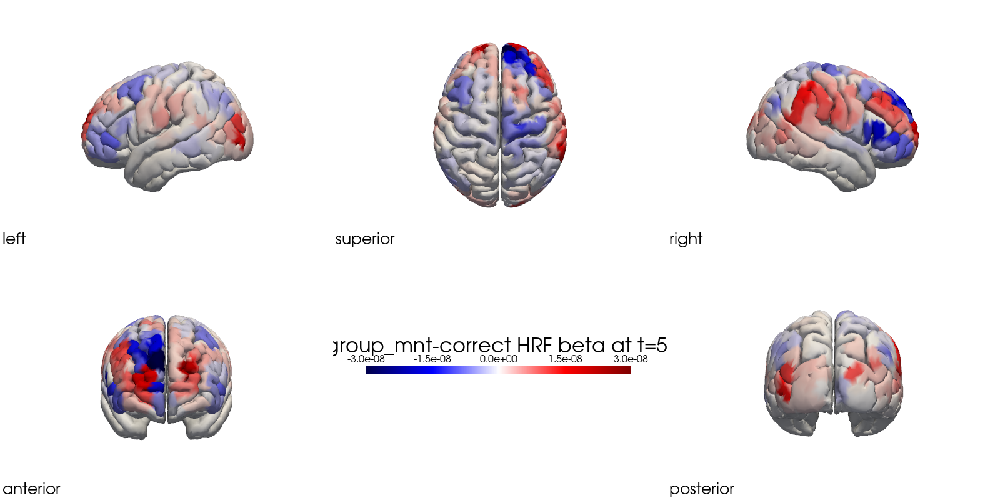

In [71]:
show([
    ('Event-based mnt-correct HRF on parcels (HRF only, AR-IRLS), group beta at 5 s. Mixed-sign, patchy map; prefrontal parcels are the strongest.',
     os.path.join(G, 'event-based_onParcel_onlyStim/mnt-correct/group_mnt-correct_t5s.png')),
])

### Stage 3: Continuous-EEG GLM (Aug – Sep 2026)
- **Design.** The continuous Cz EEG, delayed 0–15 s and projected on 15 cubic B-splines, is the regressor, so the HRF is in M/V.
- **Fitting.** Three-stage: OLS drift → OLS GSR → AR-IRLS. Main script: [run_model_cont_EEG_fNIRS.py](run_model_cont_EEG_fNIRS.py). It also saves the **shared `Y_all`** reused by later scripts.
- **Variants:**
  - trial-based EEG;
  - EEG + VTC;
  - resting state;
  - median band-power regressors (raw band power was unstable);
  - EEG masked to city/mnt trials ([run_model_cont_EEG_city_mnt.py](run_model_cont_EEG_city_mnt.py)).
- Early observation: AR-IRLS gave an HRF where OLS did not (`6db6bf3`).

**Continuous Cz-EEG HRF (AR-IRLS), group mean at SomMotA_25_LH near Cz (N = 6). M/V; multi-peaked.**  
<sub>`/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/HRF_surf/group/cont_EEG_cz/near_Cz/SomMotA_25_LH_HRF.png`</sub>

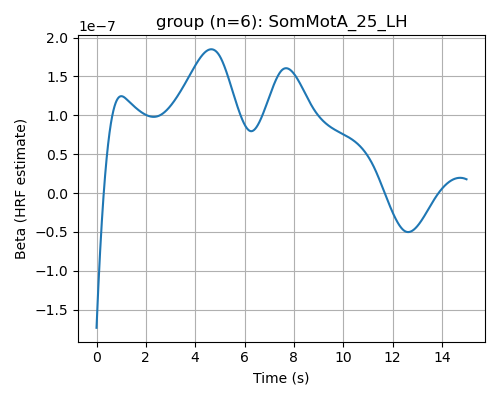

**Explained variance by network (N = 6). EV is about 0 or negative everywhere. The very large negative values (SomMotB, ContA) suggest an EV computation or outlier problem rather than a real effect (cf. commit `3a4f72f`).**  
<sub>`/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/EV_surf/group_EV_by_network.png`</sub>

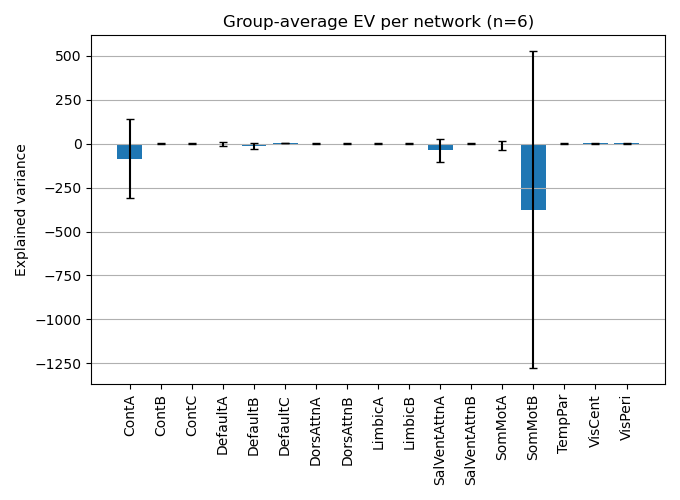

In [72]:
show([
    ('Continuous Cz-EEG HRF (AR-IRLS), group mean at SomMotA_25_LH near Cz (N = 6). M/V; multi-peaked.',
     os.path.join(G, 'cont_EEG_cz/near_Cz/SomMotA_25_LH_HRF.png')),
    ('Explained variance by network (N = 6). EV is about 0 or negative everywhere. The very large negative values (SomMotB, ContA) suggest an EV computation or outlier problem rather than a real effect (cf. commit `3a4f72f`).',
     os.path.join(D, 'EV_surf/group_EV_by_network.png')),
])

### Stage 4: Structure of the EEG HRF (Sep 2026)
- SVD/ICA of each subject's parcel × delay HRF matrix, then a joint SVD across subjects ([xSubj_shared_HRF_analysis.py](xSubj_shared_HRF_analysis.py)).
- The hope that **a few shared HRF shapes** exist motivated a low-rank model.

**Joint SVD across 6 subjects, component 0 (60% of the variance): a broad 5–10 s shared shape. The idea that a few shared shapes exist led to iRRR.**  
<sub>`/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/components_analysis/joint_svd_component0_avg_U_weight.png`</sub>

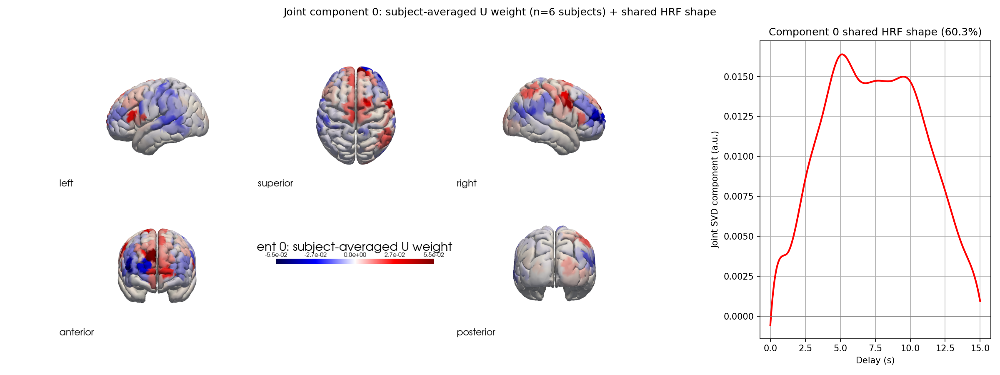

**Group iRRR (no whitening), rank 2: shared HRF components and their parcel weights.**  
<sub>`/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/HRF_surf/group/cont_EEG_cz_3-stage_iRRR/group_iRRR_shared_HRF_components.png`</sub>

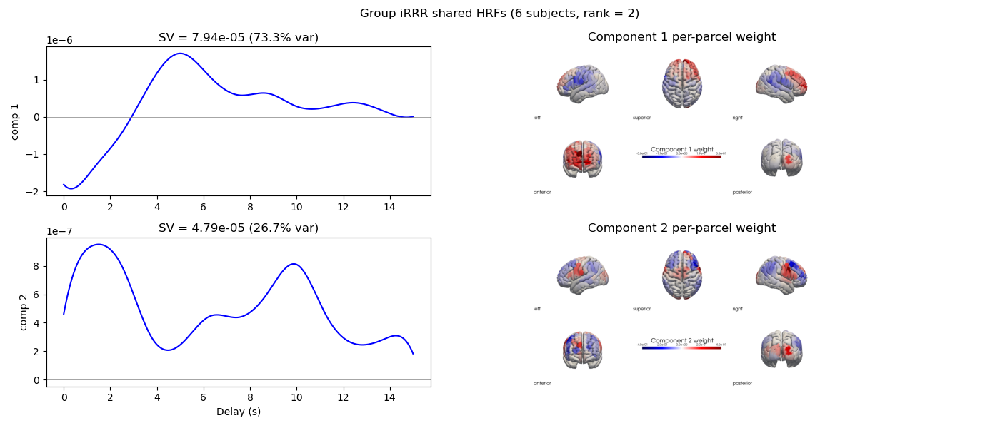

In [73]:
show([
    ('Joint SVD across 6 subjects, component 0 (60% of the variance): a broad 5–10 s shared shape. The idea that a few shared shapes exist led to iRRR.',
     os.path.join(D, 'components_analysis/joint_svd_component0_avg_U_weight.png')),
    ('Group iRRR (no whitening), rank 2: shared HRF components and their parcel weights.',
     os.path.join(G, 'cont_EEG_cz_3-stage_iRRR/group_iRRR_shared_HRF_components.png')),
])

### Stage 5: iRRR and spectral whitening (late Sep – early Oct 2026)
- **Model.** iRRR fits all parcels jointly with a nuclear-norm penalty.
- **Problem.** Applying AR-IRLS's per-parcel AR filter to Y (but not X) removed the low-frequency EEG content (`33bb9bb`).
- **Fix.** One **spectral whitening kernel**, estimated from the OLS residuals averaged over parcels and applied to *both* Y and X. This gave two models:
  - **fixAR-IRLS:** robust IRLS per parcel;
  - **AR-iRRR:** iRRR on the same whitened data.
- **Y must be scaled.** Unscaled, statsmodels `RLM` stops after 2 iterations (an unconverged, nearly-OLS fit), and a fixed λ₁ = 1 zeroes out iRRR.
- **λ₁ by CV.** Rank 0 for 3 of 6 subjects. Mean in-sample R² is 0.0043 (fixAR-IRLS) vs 0.0014 (AR-iRRR).
- iRRR components differ between subjects.
- Write-up: [summary_Hp_fixAR-IRLS_iRRR_AR.ipynb](summary_Hp_fixAR-IRLS_iRRR_AR.ipynb).

**AR-iRRR λ₁ vs cross-validated PMSE. 3 of 6 subjects have their minimum at rank 0.**  
<sub>`/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/HRF_surf/group/cont_EEG_cz_3-stage_model_cmp/summary_Hp/irrr_lam1_vs_PMSE.png`</sub>

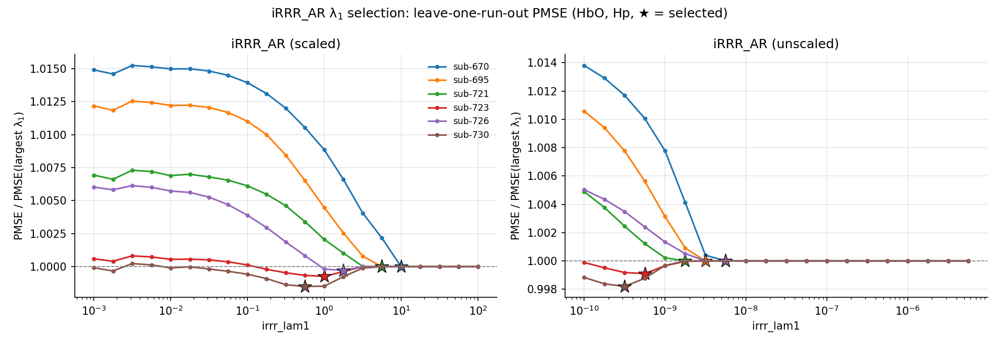

**In-sample R² and RMSE: fixAR-IRLS vs AR-iRRR, scaled and unscaled Y. R² < 1%.**  
<sub>`/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/HRF_surf/group/cont_EEG_cz_3-stage_model_cmp/summary_Hp/bar_r2_rmse.png`</sub>

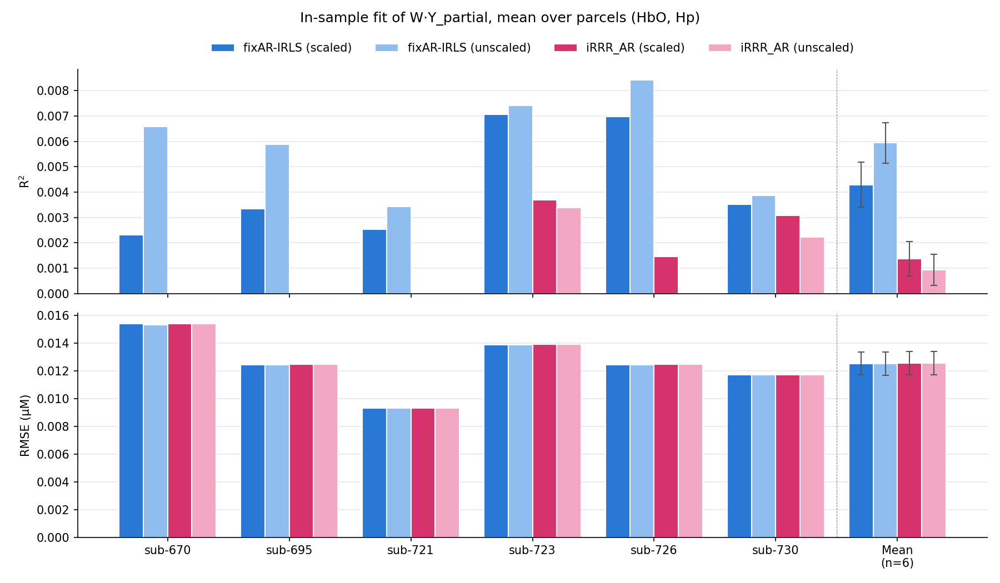

**HRFs at the 5 parcels nearest Cz.**  
<sub>`/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/HRF_surf/group/cont_EEG_cz_3-stage_model_cmp/summary_Hp/hrf_5_parcels_nearest_Cz.png`</sub>

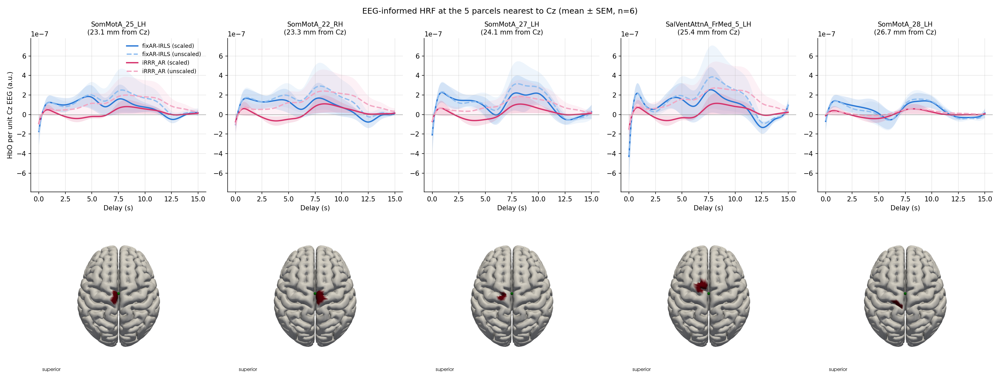

**AR-iRRR (scaled) components per subject. The shapes differ across subjects.**  
<sub>`/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/HRF_surf/group/cont_EEG_cz_3-stage_model_cmp/summary_Hp/irrr_components_iRRR_AR_scaled.png`</sub>

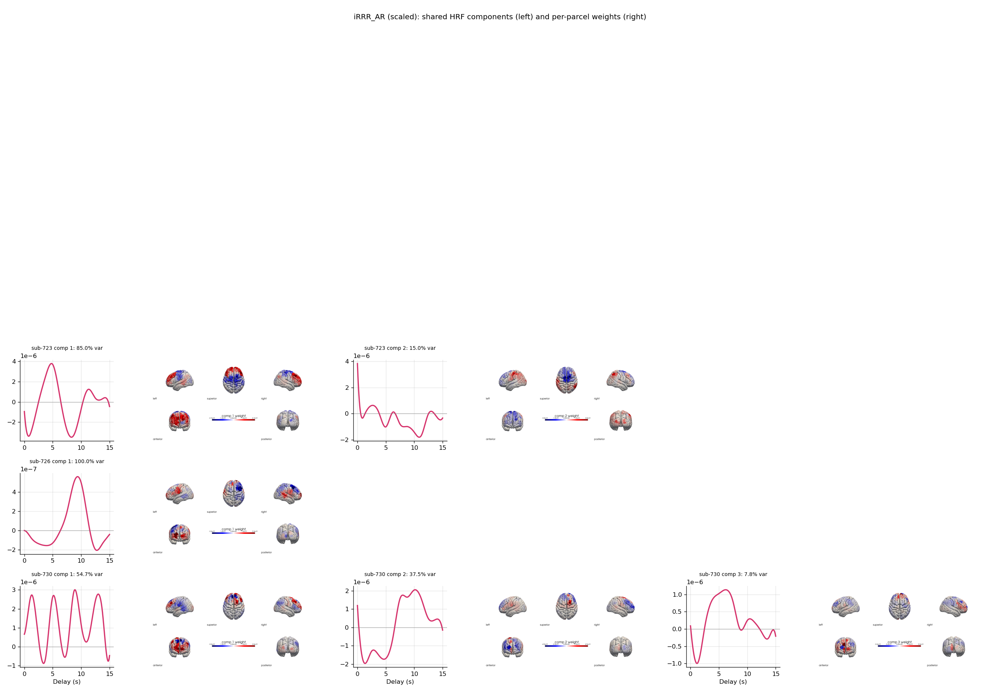

In [74]:
show([
    ('AR-iRRR λ₁ vs cross-validated PMSE. 3 of 6 subjects have their minimum at rank 0.',
     os.path.join(G, 'cont_EEG_cz_3-stage_model_cmp/summary_Hp/irrr_lam1_vs_PMSE.png')),
    ('In-sample R² and RMSE: fixAR-IRLS vs AR-iRRR, scaled and unscaled Y. R² < 1%.',
     os.path.join(G, 'cont_EEG_cz_3-stage_model_cmp/summary_Hp/bar_r2_rmse.png')),
    ('HRFs at the 5 parcels nearest Cz.',
     os.path.join(G, 'cont_EEG_cz_3-stage_model_cmp/summary_Hp/hrf_5_parcels_nearest_Cz.png')),
    ('AR-iRRR (scaled) components per subject. The shapes differ across subjects.',
     os.path.join(G, 'cont_EEG_cz_3-stage_model_cmp/summary_Hp/irrr_components_iRRR_AR_scaled.png')),
])

### Stage 6: Generalization, 6 subjects (Oct 2026)
- **Part A (train on gradcpt1, test on gradcpt2/3):**
  - test R² ≈ 0 or negative for both models and both designs (Cz EEG, mnt-correct Gaussian kernels);
  - AR-iRRR "wins" only by shrinking toward the null fit;
  - training R² rises with rank while test R² falls, which is the overfitting signature.
- **Part B (all runs, in-sample):**
  - R² is 0.001–0.019 (Cz EEG) and ≤ 0.003 (mnt-correct);
  - the run-1 HRFs agree only partly with the all-runs HRFs (median r 0.58–0.94 for fixAR-IRLS).
- Write-up: [summary_cmp_fixAR-IRLS_AR-iRRR_single-subj.ipynb](summary_cmp_fixAR-IRLS_AR-iRRR_single-subj.ipynb).

**Part A: train (gradcpt1) vs test (gradcpt2/3) R² and relative PMSE. Test R² is ≤ 0.**  
<sub>`/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/HRF_surf/group/cmp_fixAR-IRLS_AR-iRRR_single-subj/train_test_R2_PMSE.png`</sub>

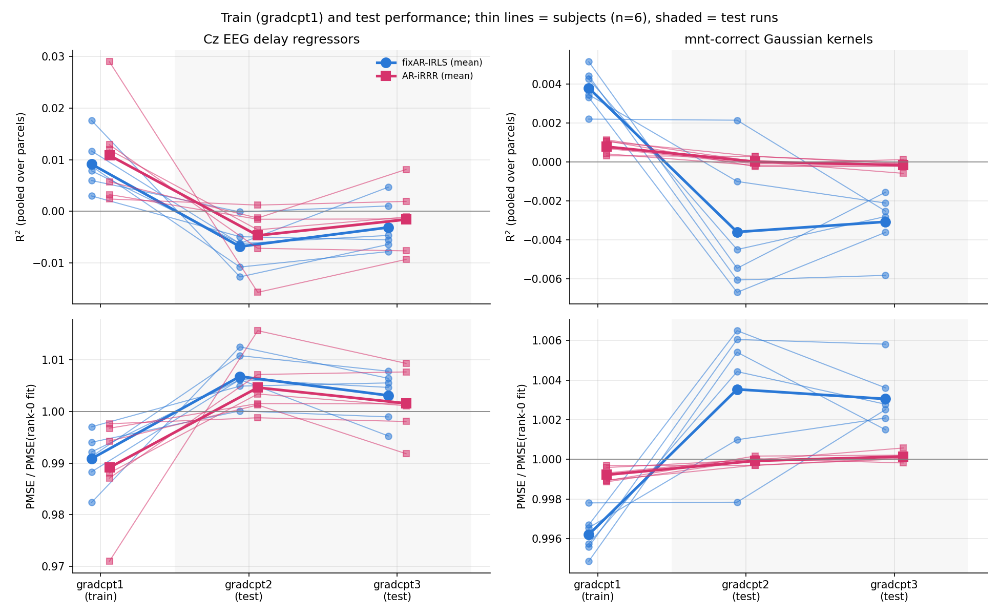

**Part A: iRRR rank sweep. Training R² rises with rank while test R² falls.**  
<sub>`/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/HRF_surf/group/cmp_fixAR-IRLS_AR-iRRR_single-subj/iRRR_rank_sweep.png`</sub>

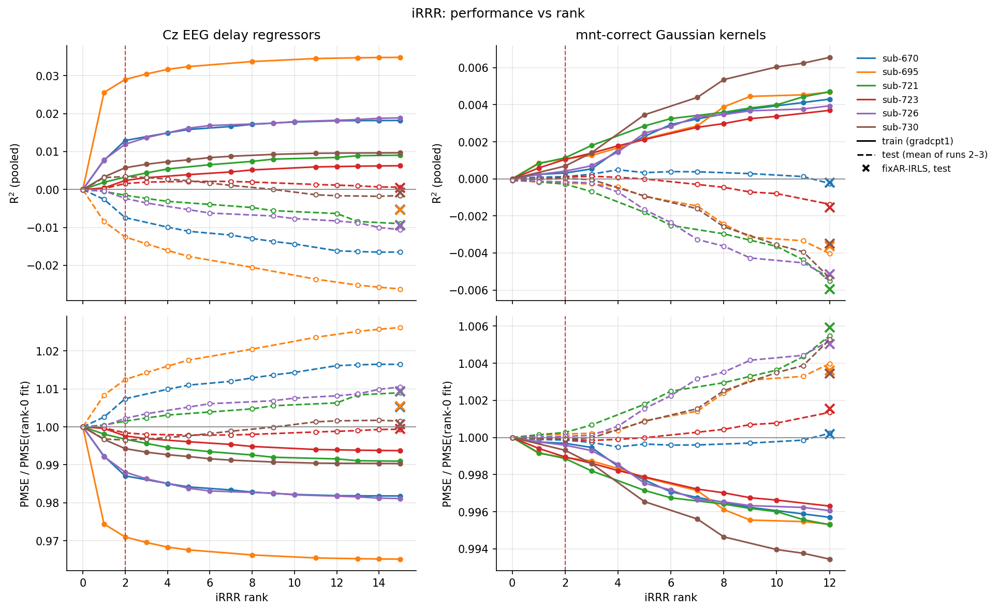

**Part B: in-sample R² and PMSE on all runs.**  
<sub>`/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/HRF_surf/group/cmp_fixAR-IRLS_AR-iRRR_single-subj/allRuns_insample_R2_PMSE.png`</sub>

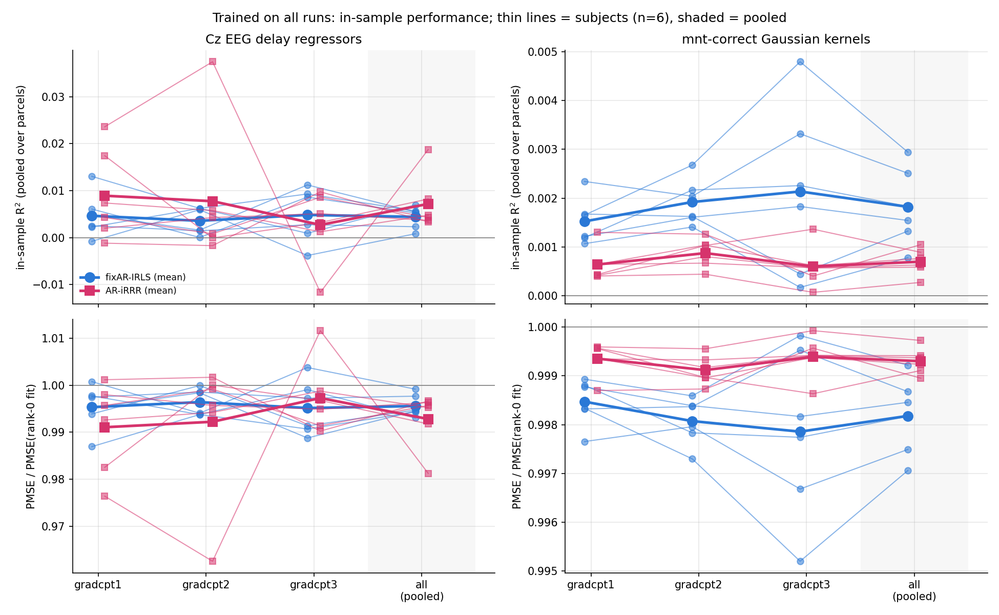

**HRF agreement, gradcpt1 vs all runs.**  
<sub>`/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/HRF_surf/group/cmp_fixAR-IRLS_AR-iRRR_single-subj/hrf_agreement_gradcpt1_vs_allRuns.png`</sub>

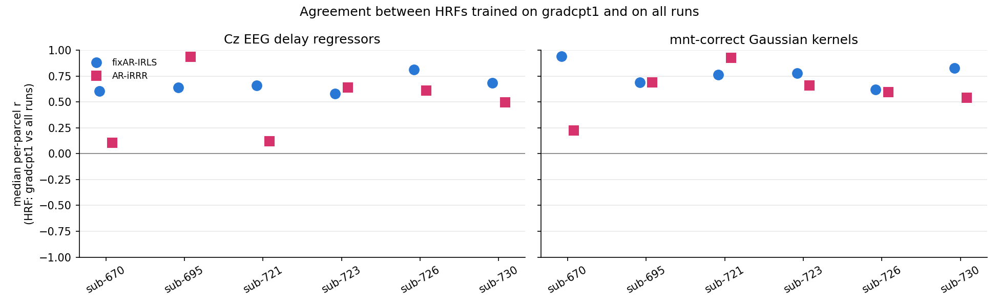

In [75]:
show([
    ('Part A: train (gradcpt1) vs test (gradcpt2/3) R² and relative PMSE. Test R² is ≤ 0.',
     os.path.join(G, 'cmp_fixAR-IRLS_AR-iRRR_single-subj/train_test_R2_PMSE.png')),
    ('Part A: iRRR rank sweep. Training R² rises with rank while test R² falls.',
     os.path.join(G, 'cmp_fixAR-IRLS_AR-iRRR_single-subj/iRRR_rank_sweep.png')),
    ('Part B: in-sample R² and PMSE on all runs.',
     os.path.join(G, 'cmp_fixAR-IRLS_AR-iRRR_single-subj/allRuns_insample_R2_PMSE.png')),
    ('HRF agreement, gradcpt1 vs all runs.',
     os.path.join(G, 'cmp_fixAR-IRLS_AR-iRRR_single-subj/hrf_agreement_gradcpt1_vs_allRuns.png')),
])

### Stage 7: AR-IRLS vs fixAR-IRLS vs AR-iRRR, event design, N = 20 (Oct 2026)
- **Design.** Gaussian kernels at mnt-correct onsets, no EEG.
- **Shape agreement.** Median per-parcel r: AR-IRLS vs fixAR-IRLS **0.87**, AR-IRLS vs AR-iRRR 0.70, fixAR-IRLS vs AR-iRRR 0.77.
- **Amplitude.** fixAR-IRLS is ~19% smaller than AR-IRLS; AR-iRRR is ~4× smaller.
- **Group HRF.** The ContA network-mean HRF peaks at ~4.5 s and dips at ~8 s (r = 0.98 between the two IRLS models).
- **Outliers:** sub-751, sub-719.
- Also compared against the coworker's Cedalion pipeline ([cmp_Cedalion-pipe_My-pipe.py](cmp_Cedalion-pipe_My-pipe.py)).
- Write-up: [summary_cmp_AR-IRLS_fixAR-IRLS_AR-iRRR.ipynb](summary_cmp_AR-IRLS_fixAR-IRLS_AR-iRRR.ipynb).
- Held-out rank sweep on the same design (city_mnt §14g): best test rank 0 for 14/20 subjects, 1 for 4/20. fixAR-IRLS and AR-IRLS have negative test R² in nearly all subjects.

**Per-parcel HRF shape r between the three models (N = 20).**  
<sub>`/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/HRF_surf/group/mnt-correct_gauss_cmp_AR-IRLS_fixAR-IRLS_AR-iRRR/summary_nb/hrf_corr_box_hist.png`</sub>

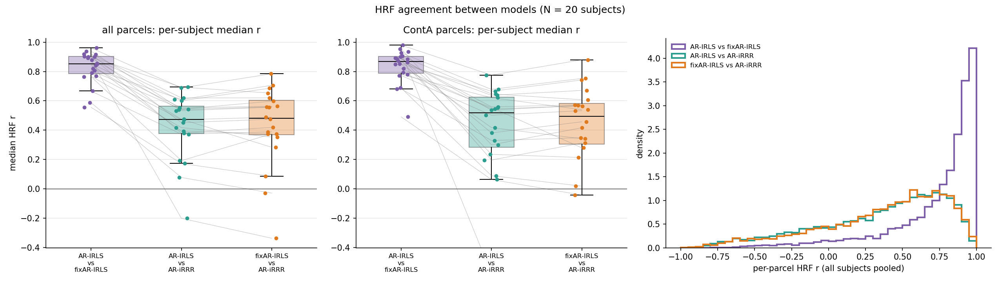

**HRF amplitude ratios. fixAR-IRLS ≈ 0.81× and AR-iRRR ≈ 0.23× AR-IRLS.**  
<sub>`/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/HRF_surf/group/mnt-correct_gauss_cmp_AR-IRLS_fixAR-IRLS_AR-iRRR/summary_nb/hrf_amplitude.png`</sub>

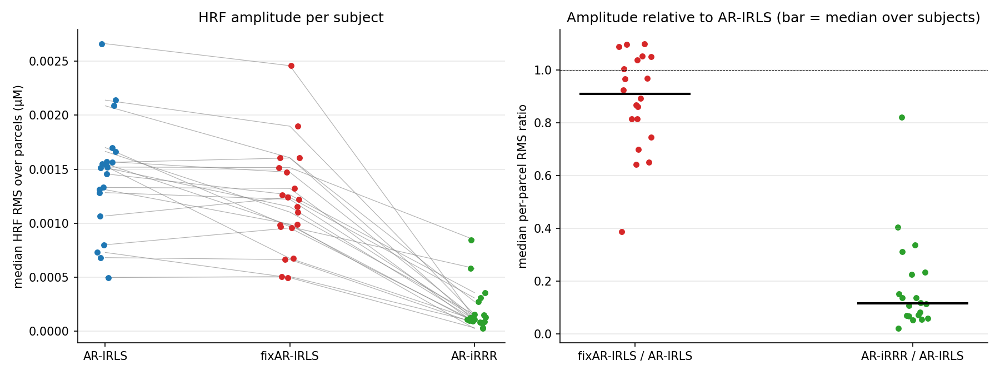

**Group ContA network-mean HRF: peak at ~4.5 s, dip at ~8 s.**  
<sub>`/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/HRF_surf/group/mnt-correct_gauss_cmp_AR-IRLS_fixAR-IRLS_AR-iRRR/summary_nb/group_hrf.png`</sub>

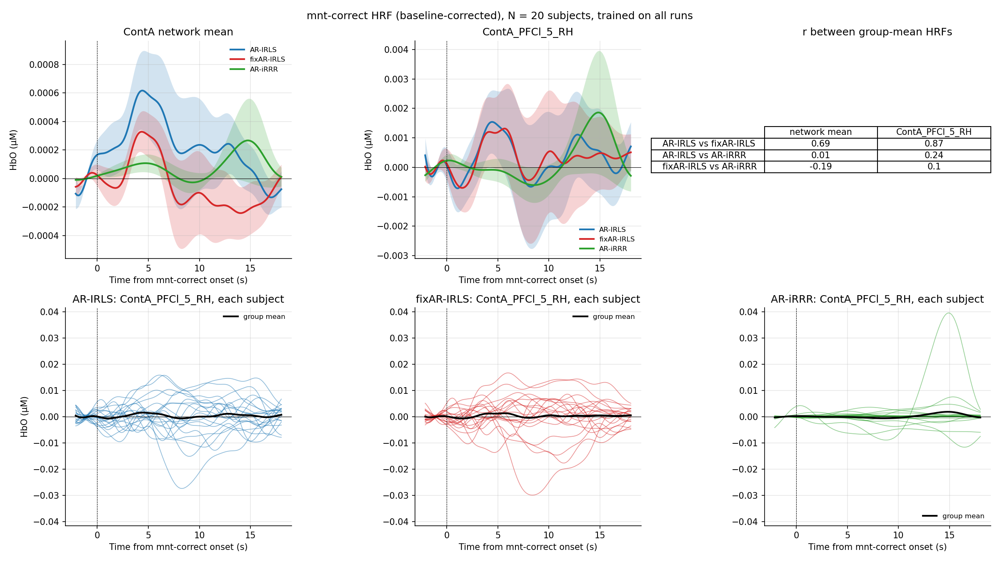

**Group mnt-correct HRF of the 12 main networks.**  
<sub>`/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/HRF_surf/group/mnt-correct_gauss_cmp_AR-IRLS_fixAR-IRLS_AR-iRRR/summary_nb/group_hrf_12_networks.png`</sub>

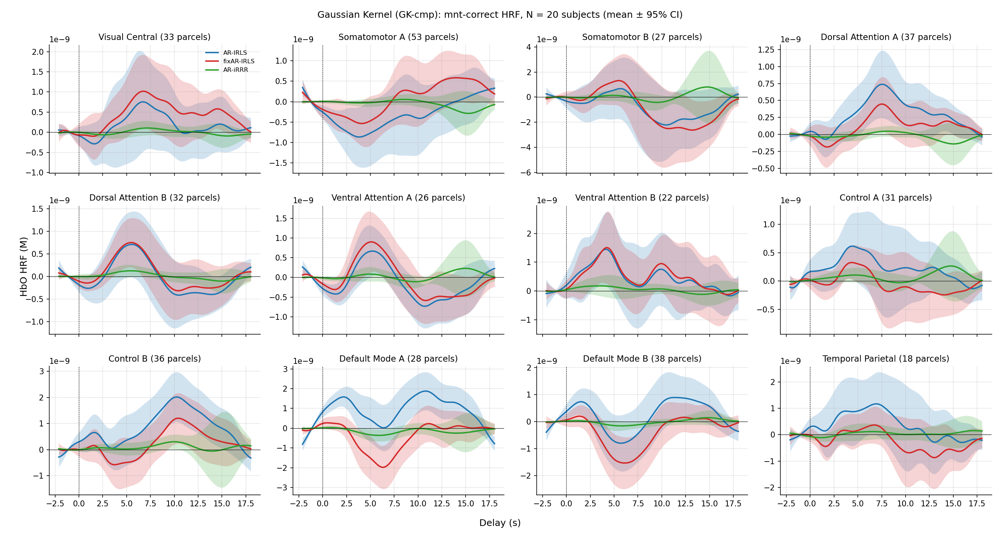

**AR-iRRR components. Component 1 carries about 90% of the energy; its shape varies across subjects.**  
<sub>`/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/HRF_surf/group/mnt-correct_gauss_cmp_AR-IRLS_fixAR-IRLS_AR-iRRR/summary_nb/irrr_components.png`</sub>

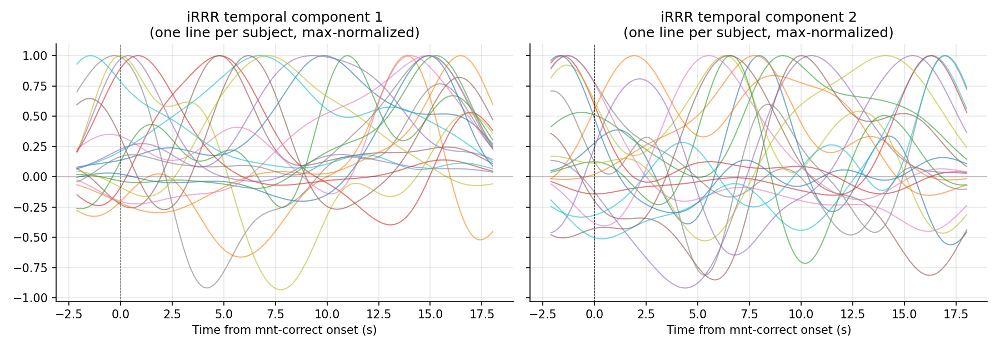

**Held-out rank sweep, trained on gradcpt1 (N = 20). The best test rank is 0 for 14 of 20 subjects.**  
<sub>`/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/HRF_surf/group/mnt-correct_gauss_cmp_AR-IRLS_fixAR-IRLS_AR-iRRR_rank_sweep/summary_nb/iRRR_rank_sweep_train-gradcpt1.png`</sub>

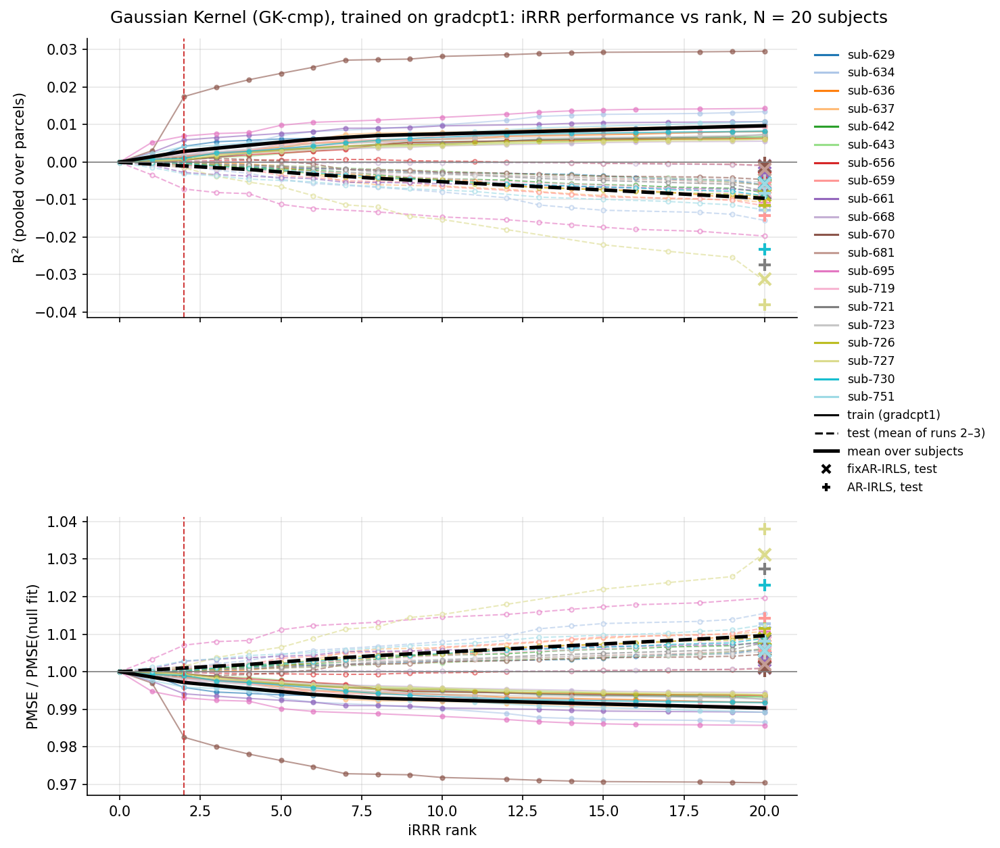

In [76]:
show([
    ('Per-parcel HRF shape r between the three models (N = 20).',
     os.path.join(G, 'mnt-correct_gauss_cmp_AR-IRLS_fixAR-IRLS_AR-iRRR/summary_nb/hrf_corr_box_hist.png')),
    ('HRF amplitude ratios. fixAR-IRLS ≈ 0.81× and AR-iRRR ≈ 0.23× AR-IRLS.',
     os.path.join(G, 'mnt-correct_gauss_cmp_AR-IRLS_fixAR-IRLS_AR-iRRR/summary_nb/hrf_amplitude.png')),
    ('Group ContA network-mean HRF: peak at ~4.5 s, dip at ~8 s.',
     os.path.join(G, 'mnt-correct_gauss_cmp_AR-IRLS_fixAR-IRLS_AR-iRRR/summary_nb/group_hrf.png')),
    ('Group mnt-correct HRF of the 12 main networks.',
     os.path.join(G, 'mnt-correct_gauss_cmp_AR-IRLS_fixAR-IRLS_AR-iRRR/summary_nb/group_hrf_12_networks.png')),
    ('AR-iRRR components. Component 1 carries about 90% of the energy; its shape varies across subjects.',
     os.path.join(G, 'mnt-correct_gauss_cmp_AR-IRLS_fixAR-IRLS_AR-iRRR/summary_nb/irrr_components.png')),
    ('Held-out rank sweep, trained on gradcpt1 (N = 20). The best test rank is 0 for 14 of 20 subjects.',
     os.path.join(G, 'mnt-correct_gauss_cmp_AR-IRLS_fixAR-IRLS_AR-iRRR_rank_sweep/summary_nb/iRRR_rank_sweep_train-gradcpt1.png')),
])

### Stage 8: Network-based fits and the four-way mnt-correct comparison (late Oct 2026)
**Network-based fits.** Each of the 17 networks gets its own whitening kernel, `Y_scale` and iRRR.
- Continuous Cz EEG design ([summary_AR-iRRR_fixAR-IRLS_network-based.ipynb](summary_AR-iRRR_fixAR-IRLS_network-based.ipynb)):
  - rank 2 is reached in every network;
  - AR-iRRR vs fixAR-IRLS: median r = 0.66, RMS ratio 0.60;
  - 68% of parcels have p < 0.05 in the fixAR-IRLS F-test, which is likely anti-conservative.

**Four-way mnt-correct comparison** ([summary_run_model_cont_EEG_city_mnt.ipynb](summary_run_model_cont_EEG_city_mnt.ipynb), §15; N = 5 common subjects). The four scripts are `city`, `EEG-net`, `GK-net` and `GK-cmp`.

**Fraction of parcels with p < 0.05 per subject** (chance = 0.05):

| Script | Design | p < 0.05 | FDR q < 0.05 |
|---|---|---|---|
| `city` | EEG within trials, mnt-correct block | 0.11–0.41 (by model) | — |
| `EEG-net` | EEG within mnt-correct trials | 0.21–0.37 | 0.09–0.30 |
| `GK-net` | Gaussian kernels, no EEG | 0.24–0.58 | 0.15–0.53 |

- The strongest `GK-net` parcels are prefrontal: ContA_PFClv_1_LH, DefaultA_PFCm_7_RH, ContA_PFCl_3_RH. These are significant in every subject.

**Model agreement within `city`.** AR-IRLS vs fixAR-IRLS median r = 0.91 (mnt-correct) and 0.90 (mnt-incorrect). AR-iRRR vs either: ≈ 0.4.

**Shape agreement across scripts** (median per-parcel r):
- **The same design under a different pipeline agrees well:** `city` vs `EEG-net` (fixAR-IRLS) r = 0.94; `GK-net` vs `GK-cmp` (fixAR-IRLS) r = 0.96.
- **A different design under the same pipeline does not:** `EEG-net` vs `GK-net` r ≈ 0.1–0.25.
- So the EEG-weighted HRF is a different object from the event-locked HRF.

**Peak latency.** The event-based HRFs peak at ~6 s in the visual, somatomotor, attention and salience networks. The fixAR-IRLS EEG-weighted HRFs often peak at **0–2 s** (VisCent, SomMotA/B, DorsAttnB, SalVentAttnA, TempPar). That is too early for a hemodynamic response and needs checking.

**Alignment caveat.** `city` outputs predate the alignment fix `e99d06d` and must be rerun. `EEG-net`, `GK-net` and `GK-cmp` were saved after it. §16 (the written summary) is still empty.

**Network-based Cz-EEG model: AR-iRRR vs fixAR-IRLS shape and amplitude agreement per network.**  
<sub>`/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/HRF_surf/group/cont_EEG_cz_3-stage_AR-iRRR_vs_fixAR-IRLS-network_Hp/agreement_by_network.png`</sub>

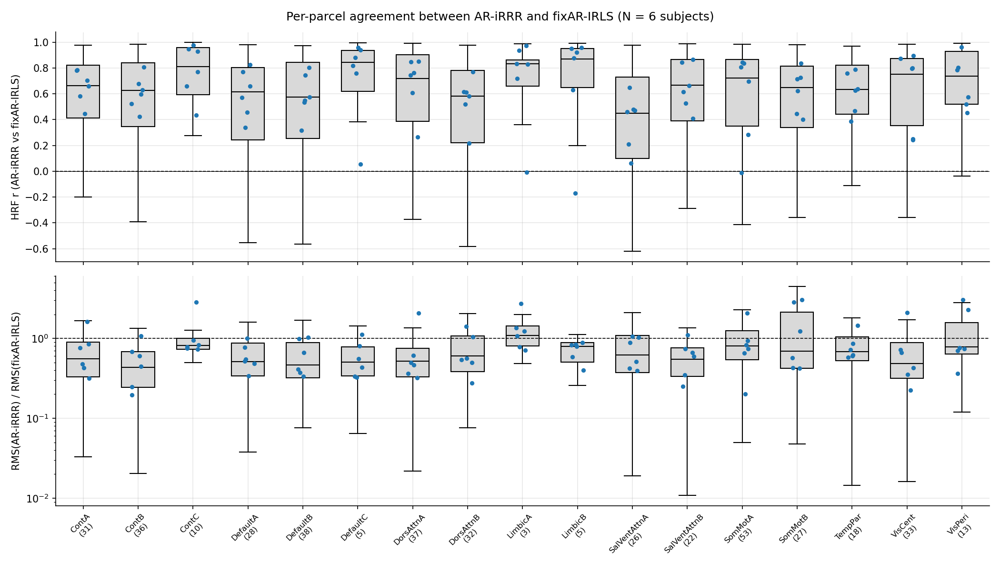

**Network-based Cz-EEG model: fraction of parcels with a significant fixAR-IRLS F-test (likely anti-conservative).**  
<sub>`/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/HRF_surf/group/cont_EEG_cz_3-stage_AR-iRRR_vs_fixAR-IRLS-network_Hp/ftest_frac_sig.png`</sub>

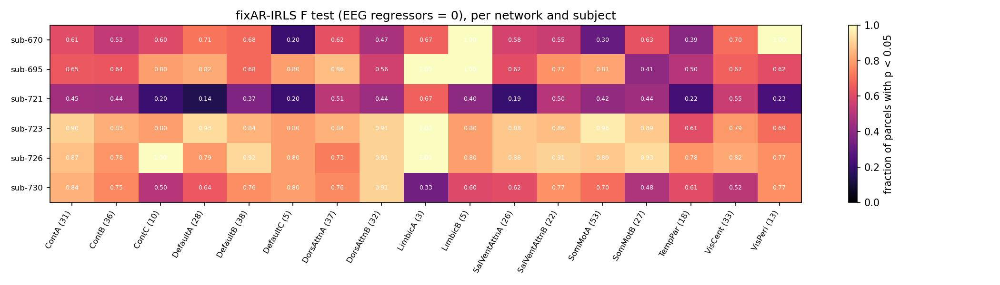

**`city`: F-test fraction of significant parcels per subject, model and trial type (pre-alignment-fix).**  
<sub>`/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/HRF_surf/group/cont_EEG_cz_mnt_correct_incorrect_pre2post18/summary_nb/ftest_frac_sig.png`</sub>

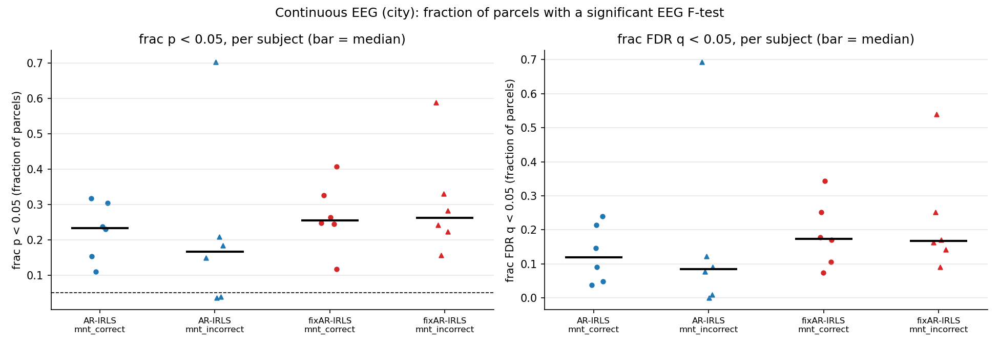

**`city`: group mnt-correct HRF of the 12 main networks, three models (M/V, pre-alignment-fix).**  
<sub>`/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/HRF_surf/group/cont_EEG_cz_mnt_correct_incorrect_pre2post18/summary_nb/group_hrf_12_networks_mnt_correct.png`</sub>

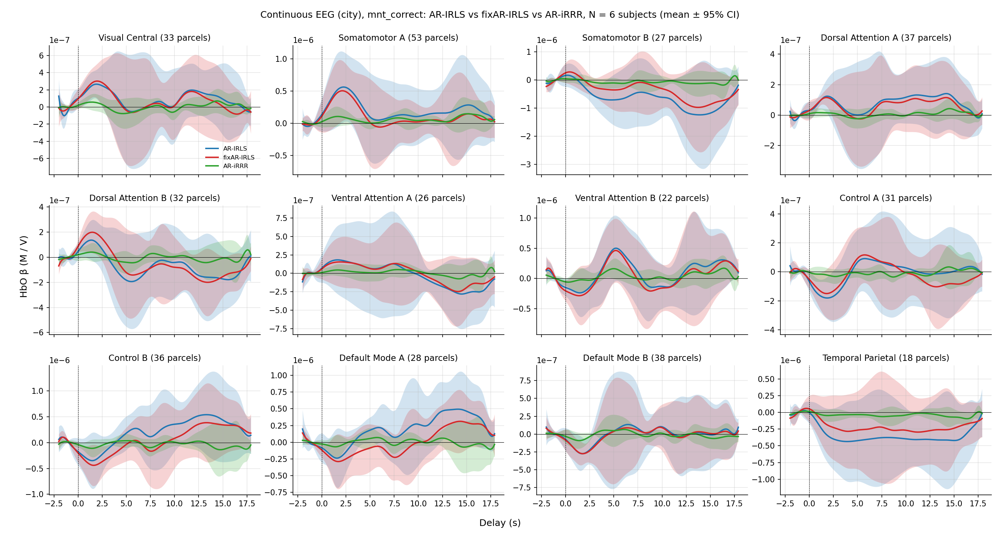

**`GK-net`: event-locked mnt-correct HRF of the 12 main networks (M).**  
<sub>`/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/HRF_surf/group/mnt-correct_gauss_3-stage/summary_nb/group_hrf_12_networks.png`</sub>

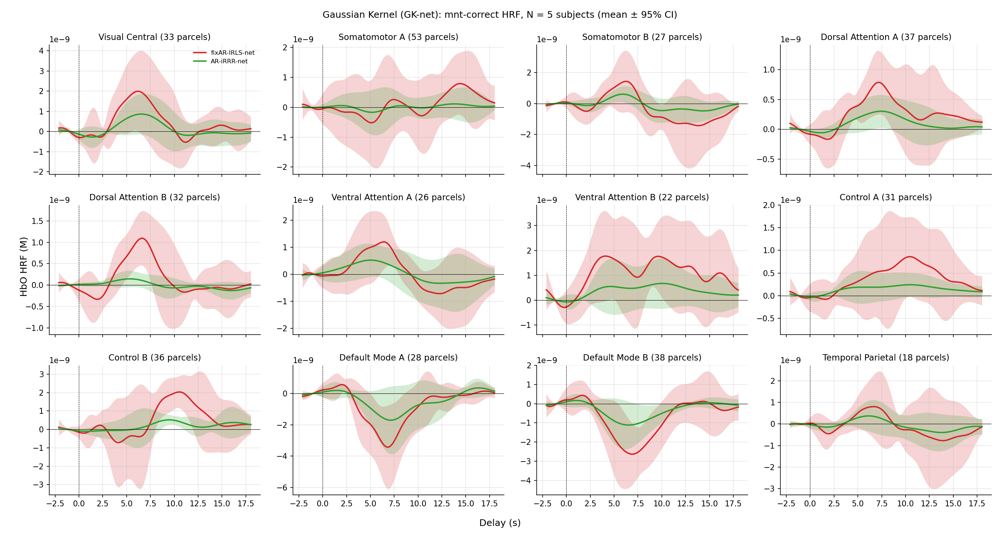

**`EEG-net`: EEG-weighted mnt-correct HRF of the 12 main networks (M/V).**  
<sub>`/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/HRF_surf/group/cont_EEG_cz_mnt-correct_pre2post18_3-stage/summary_nb/group_hrf_12_networks.png`</sub>

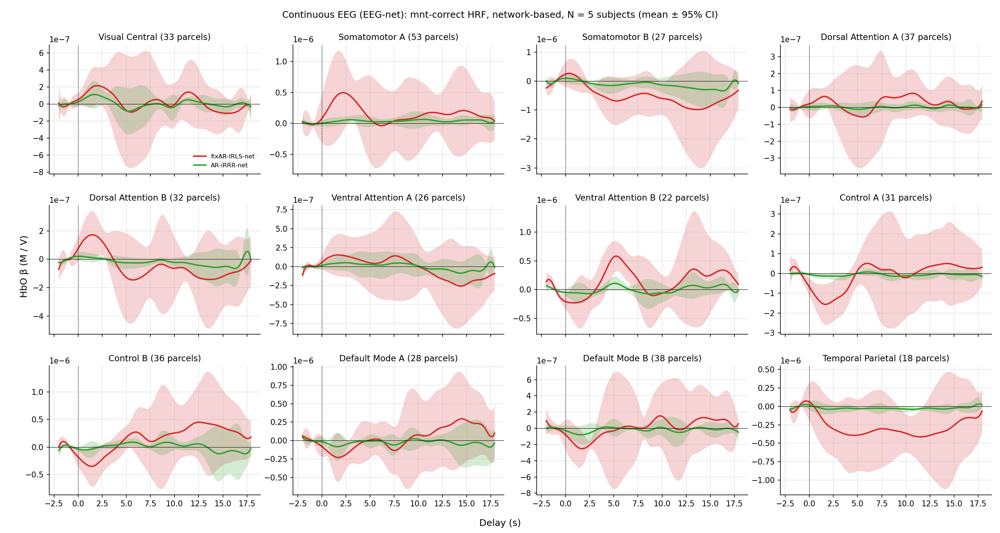

**`GK-net` vs `EEG-net`, max-normalized: same pipeline, different design. The EEG-weighted curves peak much earlier.**  
<sub>`/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/HRF_surf/group/mnt-correct_gauss_3-stage/summary_nb/group_hrf_12_networks_event_vs_eeg_norm.png`</sub>

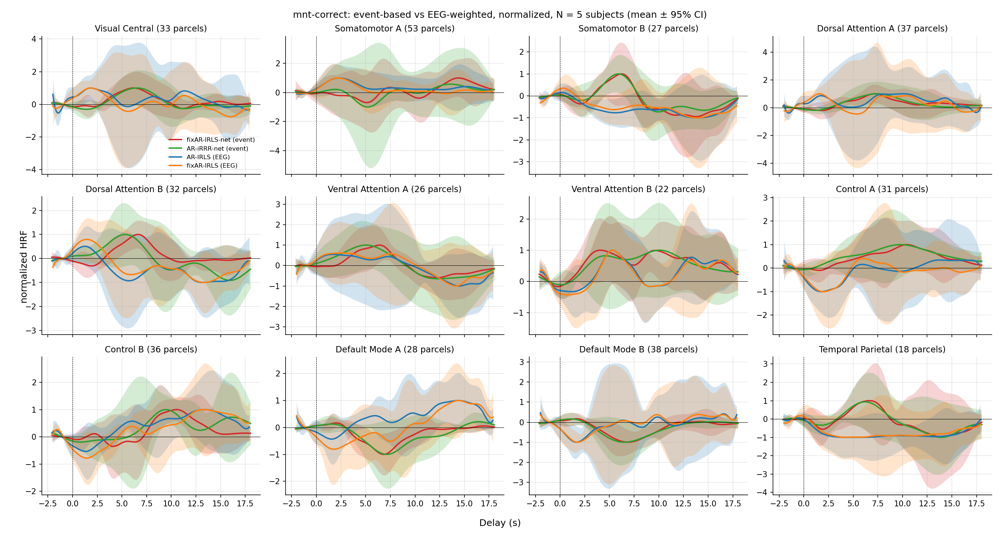

**Four-script shape agreement: blocks by design (EEG vs Gaussian kernel), not by pipeline.**  
<sub>`/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/HRF_surf/group/mnt-correct_4-script_cmp/summary_nb/hrf_corr_matrix.png`</sub>

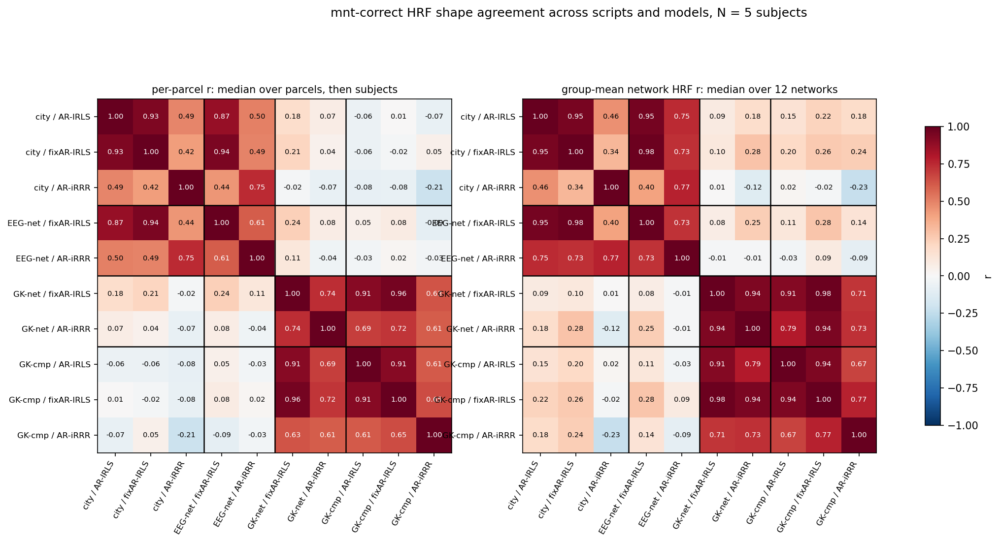

**fixAR-IRLS mnt-correct HRF of the 12 networks across the four scripts, max-normalized.**  
<sub>`/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/HRF_surf/group/mnt-correct_4-script_cmp/summary_nb/group_hrf_12_networks_fixAR-IRLS_norm.png`</sub>

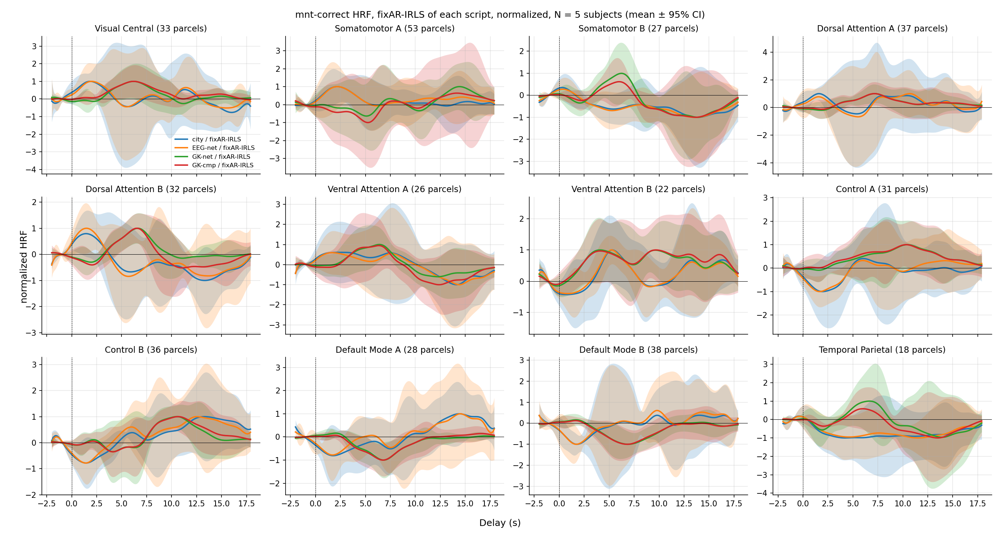

In [77]:
show([
    ('Network-based Cz-EEG model: AR-iRRR vs fixAR-IRLS shape and amplitude agreement per network.',
     os.path.join(G, 'cont_EEG_cz_3-stage_AR-iRRR_vs_fixAR-IRLS-network_Hp/agreement_by_network.png')),
    ('Network-based Cz-EEG model: fraction of parcels with a significant fixAR-IRLS F-test (likely anti-conservative).',
     os.path.join(G, 'cont_EEG_cz_3-stage_AR-iRRR_vs_fixAR-IRLS-network_Hp/ftest_frac_sig.png')),
    ('`city`: F-test fraction of significant parcels per subject, model and trial type (pre-alignment-fix).',
     os.path.join(G, 'cont_EEG_cz_mnt_correct_incorrect_pre2post18/summary_nb/ftest_frac_sig.png')),
    ('`city`: group mnt-correct HRF of the 12 main networks, three models (M/V, pre-alignment-fix).',
     os.path.join(G, 'cont_EEG_cz_mnt_correct_incorrect_pre2post18/summary_nb/group_hrf_12_networks_mnt_correct.png')),
    ('`GK-net`: event-locked mnt-correct HRF of the 12 main networks (M).',
     os.path.join(G, 'mnt-correct_gauss_3-stage/summary_nb/group_hrf_12_networks.png')),
    ('`EEG-net`: EEG-weighted mnt-correct HRF of the 12 main networks (M/V).',
     os.path.join(G, 'cont_EEG_cz_mnt-correct_pre2post18_3-stage/summary_nb/group_hrf_12_networks.png')),
    ('`GK-net` vs `EEG-net`, max-normalized: same pipeline, different design. The EEG-weighted curves peak much earlier.',
     os.path.join(G, 'mnt-correct_gauss_3-stage/summary_nb/group_hrf_12_networks_event_vs_eeg_norm.png')),
    ('Four-script shape agreement: blocks by design (EEG vs Gaussian kernel), not by pipeline.',
     os.path.join(G, 'mnt-correct_4-script_cmp/summary_nb/hrf_corr_matrix.png')),
    ('fixAR-IRLS mnt-correct HRF of the 12 networks across the four scripts, max-normalized.',
     os.path.join(G, 'mnt-correct_4-script_cmp/summary_nb/group_hrf_12_networks_fixAR-IRLS_norm.png')),
])

### Stage 9: Bayesian joint HRF + AR(P) model (2026-10-28 → 11-03, in progress)
**Motivation.** Every earlier model estimates the noise first (drift/GSR by OLS, then AR or spectral whitening) and the HRF second, so noise-model uncertainty is ignored. Here everything is sampled jointly with NUTS (PyMC).

**Model** ([run_Bayes_image-space_gaussian-kernel_mnt-correct.py](Bayesian%20model/run_Bayes_image-space_gaussian-kernel_mnt-correct.py)):

$$\tilde y = Xh + Nb + e,\quad e_t=\textstyle\sum_{k=1}^{P}\phi_k e_{t-k}+\varepsilon_t,\quad \varepsilon_t\sim\text{StudentT}(\nu,0,\sigma)$$

- **X:** 20 Gaussian kernels (−2 to 18 s) at the mnt-correct onsets.
- **N:** per-run Legendre drift (orders 0–3) plus per-run GSR, fit *jointly* (1-stage).
- **h:** h ~ N(0, τ_h), with an optional second-difference smoothness penalty.
- **AR noise:** stationary by construction (tanh(z) → partial autocorrelations → Durbin–Levinson). The likelihood is evaluated only where the P-lag history lies inside one run.
- **AR order P:** chosen beforehand from the OLS residuals (start at 10, add lags while the last one is significant, max 30).
- Full derivation: [run_Bayes_…_summary.ipynb](Bayesian%20model/run_Bayes_image-space_gaussian-kernel_mnt-correct_summary.ipynb).

**Simulation** ([example_hrf_ar_pymc.py](Bayesian%20model/example_hrf_ar_pymc.py); an earlier variant with a canonical-HRF prior mean and per-condition amplitudes):
- the 95% band covers the true HRF at 96% of lags;
- AR(2) coefficients are recovered;
- both condition amplitudes are recovered (figure in §8).

**Real data:** sub-723, gradcpt1 only, HbO; parcels DorsAttnB_PostC_2_RH and SomMotA_25_LH.
- **v1** (canonical prior + amplitude, smooth):
  - DorsAttnB HRF peaks near 5 s, close to canonical;
  - the amplitude posterior overlaps 0;
  - AR(9);
  - 25 divergences.
- **v2** (current: zero-mean ridge, no smoothness):
  - AR(14);
  - φ₁ ≈ 0.52 (DorsAttnB) and 0.73 (SomMotA);
  - DorsAttnB posterior mean: peak ~4.7 s, dip ~8 s, second bump ~12 s. That matches the ContA pattern from Stage 7, but the band contains 0 at nearly all lags;
  - SomMotA is flat;
  - for SomMotA, the nuisance + event fit does not follow the large slow swings of the data. That variance ends up in the AR noise term.

**Bookkeeping**
- The saved `.nc` posteriors in `derivatives/eeg/sub-723/bayes/` are from **v1**. v2 saved figures only (`…_Hp_noSmooth/`).
- The summary notebook lists defaults `SomMotA_25_LH` / `is_smooth_penalty=True`. The committed script uses `DorsAttnB_PostC_2_RH` / `False`.

**Simulation (example_hrf_ar_pymc.py): HRF, AR(2) coefficients and amplitudes recovered.**  
<sub>`/projectnb/nphfnirs/s/datasets/gradCPT_NN24/code/eeg/modeling/Bayesian model/hrf_ar_sim.png`</sub>

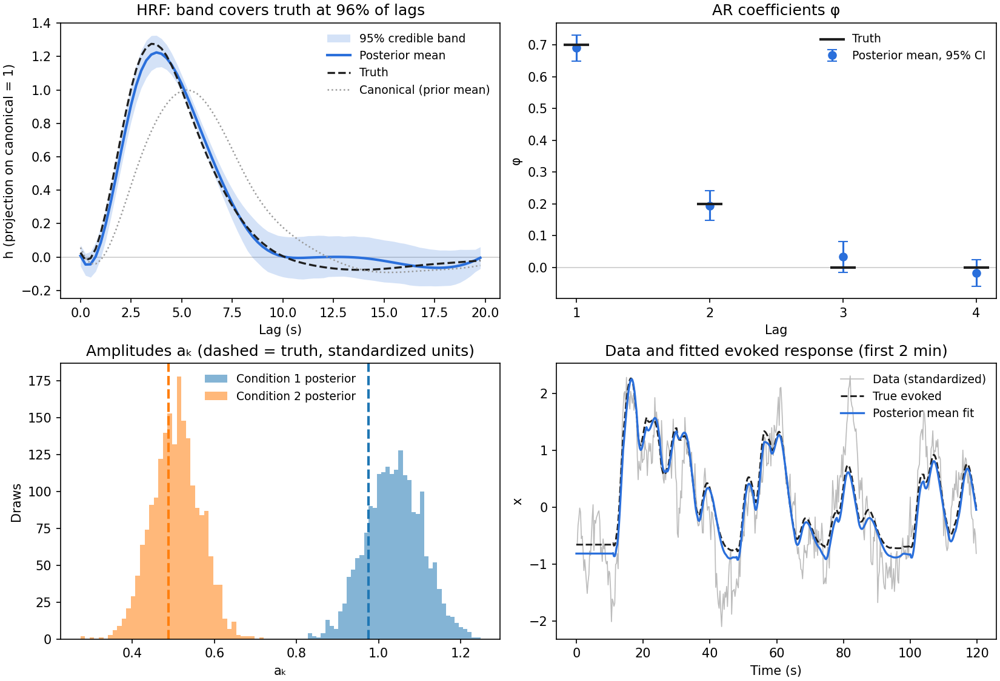

**v2 (current model), sub-723 DorsAttnB_PostC_2_RH, gradcpt1: the HRF band contains 0 at nearly all lags.**  
<sub>`/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/HRF_surf/sub-723/Bayes-HRF-AR_mnt-correct_gauss_1-stage_gradcpt1_Hp_noSmooth/sub-723_DorsAttnB_PostC_2_RH_posterior.png`</sub>

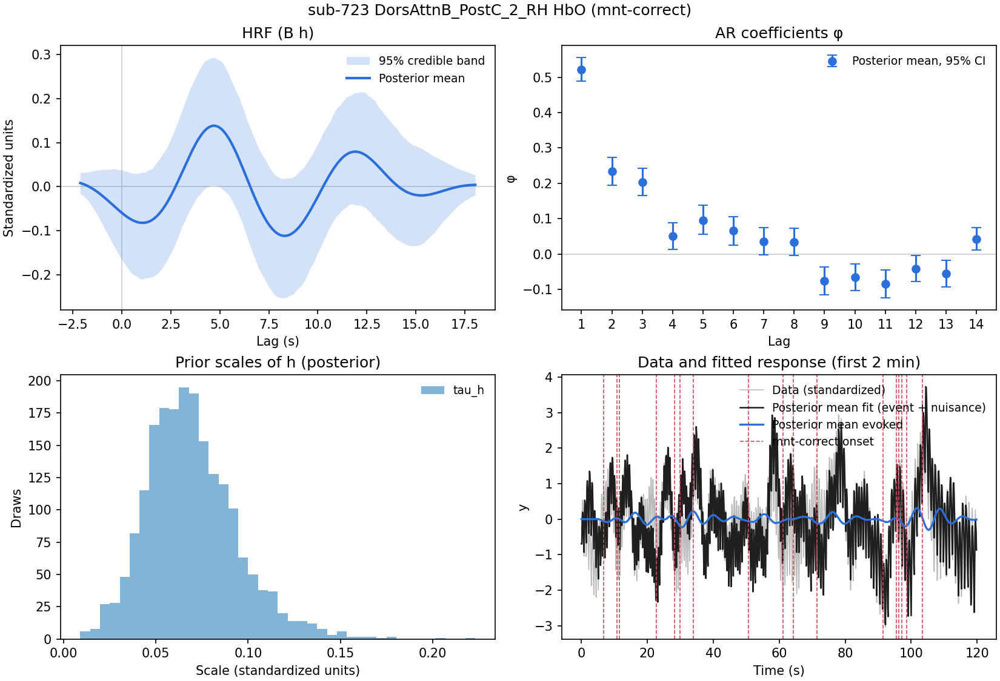

**v2, sub-723 DorsAttnB_PostC_2_RH: fit around the 3rd mnt-correct event (µM).**  
<sub>`/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/HRF_surf/sub-723/Bayes-HRF-AR_mnt-correct_gauss_1-stage_gradcpt1_Hp_noSmooth/sub-723_DorsAttnB_PostC_2_RH_event3_fit.png`</sub>

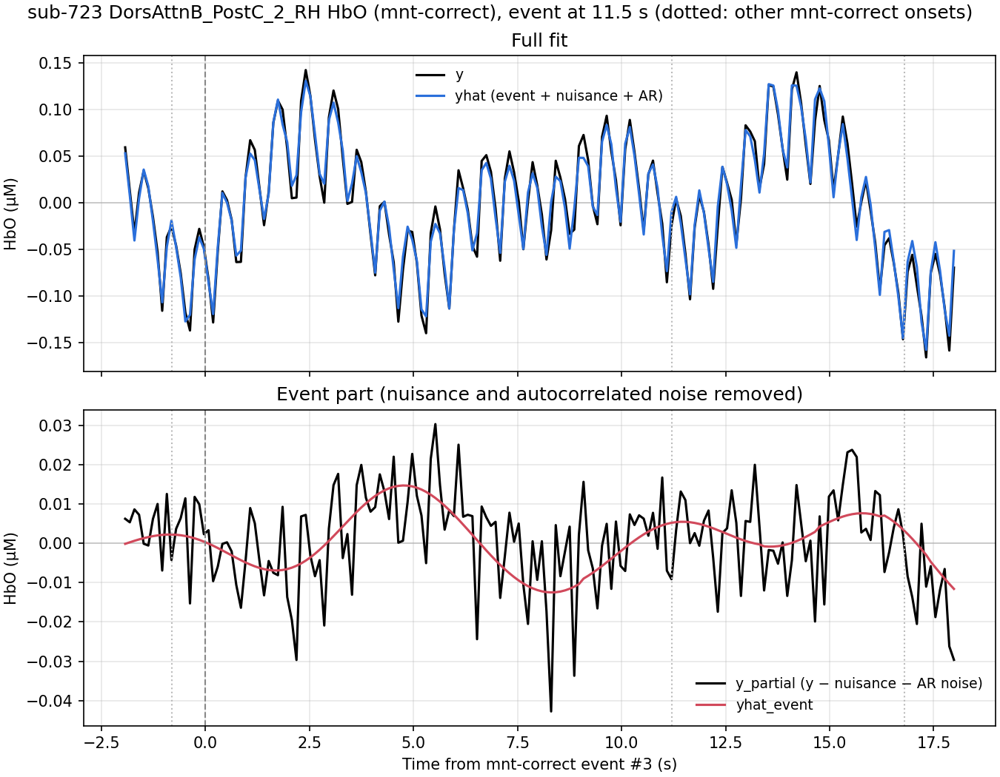

**v2, sub-723 SomMotA_25_LH: flat HRF; the slow swings go into the AR noise.**  
<sub>`/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/HRF_surf/sub-723/Bayes-HRF-AR_mnt-correct_gauss_1-stage_gradcpt1_Hp_noSmooth/sub-723_SomMotA_25_LH_posterior.png`</sub>

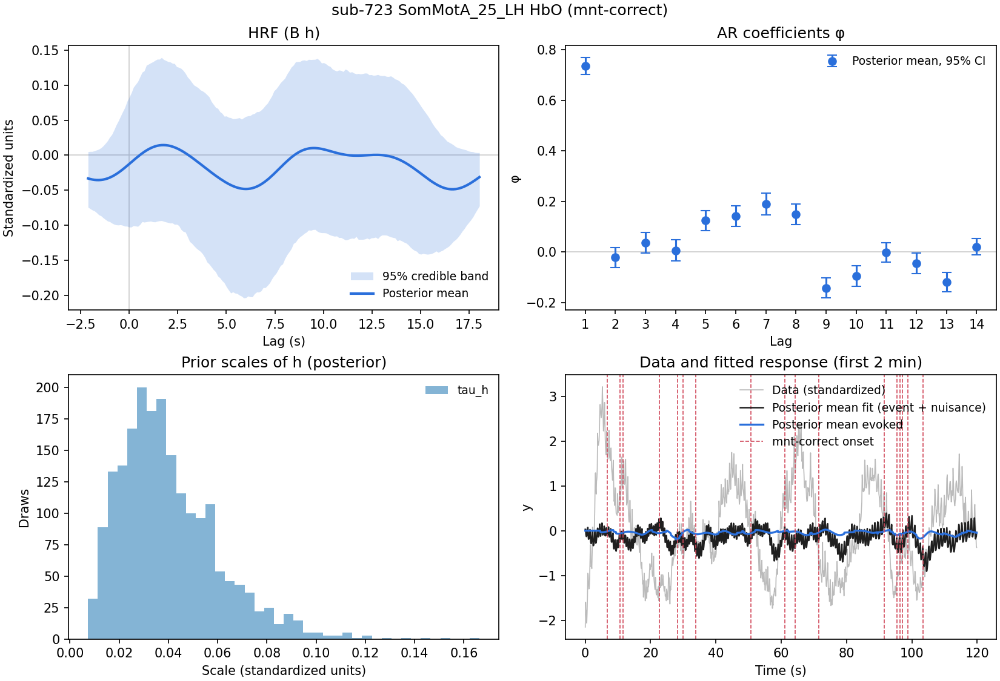

**v1 (canonical prior + amplitude, smoothness penalty), sub-723 DorsAttnB_PostC_2_RH, for comparison.**  
<sub>`/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/HRF_surf/sub-723/Bayes-HRF-AR_mnt-correct_gauss_1-stage_gradcpt1_Hp/sub-723_DorsAttnB_PostC_2_RH_posterior.png`</sub>

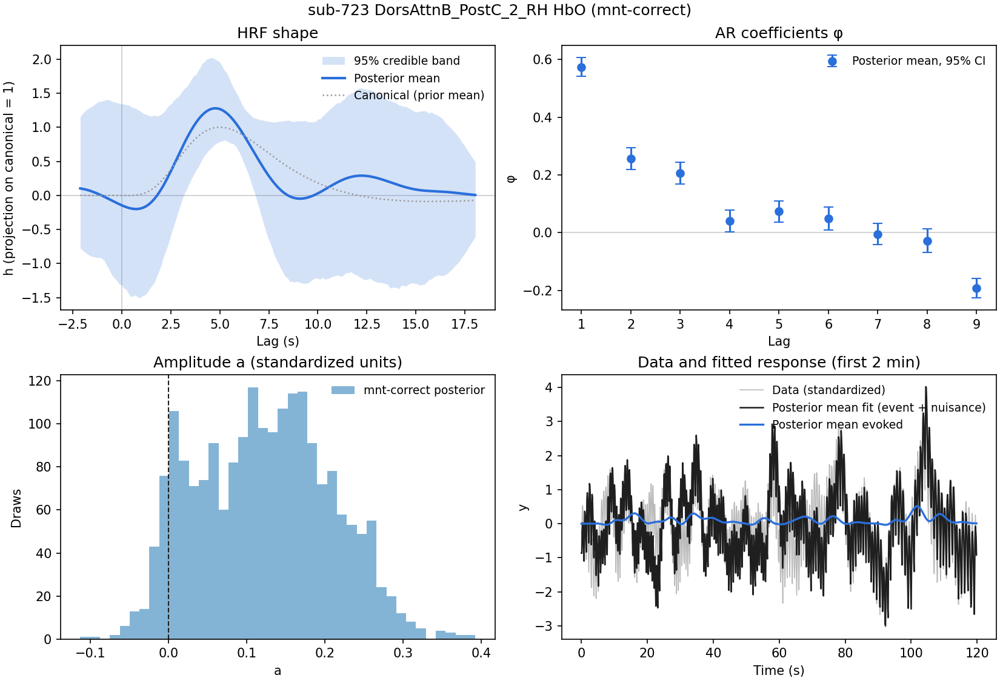

In [78]:
show([
    ('Simulation (example_hrf_ar_pymc.py): HRF, AR(2) coefficients and amplitudes recovered.',
     os.path.join(MODELING, 'Bayesian model', 'hrf_ar_sim.png')),
    ('v2 (current model), sub-723 DorsAttnB_PostC_2_RH, gradcpt1: the HRF band contains 0 at nearly all lags.',
     os.path.join(BAYES_V2, 'sub-723_DorsAttnB_PostC_2_RH_posterior.png')),
    ('v2, sub-723 DorsAttnB_PostC_2_RH: fit around the 3rd mnt-correct event (µM).',
     os.path.join(BAYES_V2, 'sub-723_DorsAttnB_PostC_2_RH_event3_fit.png')),
    ('v2, sub-723 SomMotA_25_LH: flat HRF; the slow swings go into the AR noise.',
     os.path.join(BAYES_V2, 'sub-723_SomMotA_25_LH_posterior.png')),
    ('v1 (canonical prior + amplitude, smoothness penalty), sub-723 DorsAttnB_PostC_2_RH, for comparison.',
     os.path.join(BAYES_V1, 'sub-723_DorsAttnB_PostC_2_RH_posterior.png')),
])

## 5. mnt-correct HRF across four model designs

This section compares the mnt-correct HbO HRF from four designs. **The noise model is held fixed:** all four are Cedalion AR-IRLS fits of HbO on the image-space parcels. Only the design and the preprocessing of `Y` differ.

| Tag | Script (saved model name) | Design: what the HRF multiplies | Delays | HRF unit |
|---|---|---|---|---|
| **GK_mnt-correct** | `run_model_EEG_inform_parcel_based.py`, `model_type='onlyStim'` (`event-based_onParcel_onlyStim_ar_irls_Hp`) | 12 Gaussian kernels (1 s apart, 1 s SD) at mnt-correct onsets; mnt-incorrect kernels in the same fit | −2 to 10 s | M |
| **EEG-informed-GK_mnt-correct** | same script, `model_type='full'` (`event-based_onParcel_full_ar_irls_Hp`) | the same kernels, unscaled (β_stim) **plus a copy scaled by each trial's Cz ERP area** (β_eeg). The HRF shown is the **trial-mean HRF** `B·β_stim + ā·B·β_eeg`; see the note below | −2 to 10 s | M |
| **Cont-EEG_mnt-correct** | `run_model_cont_EEG_city_mnt.py` (`city`, `cont_EEG_cz_mnt_correct_incorrect_pre2post18_ar_irls_Hp0.01`) | continuous Cz EEG **zeroed outside mnt-correct trials**, 20 B-splines; mnt-incorrect block in the same fit | −2 to 18 s | M / V |
| **Cont-EEG_entire-run** | `run_model_cont_EEG_fNIRS.py` (`cont_EEG_cz_3-stage_bspline-test_ar_irls_Hp`) | continuous Cz EEG over the **entire run**, 15 B-splines; not trial-locked | 0 to 15 s | M / V |

**The EEG-informed HRF.** This follows `vis_hrf.py`.
- Trial *i* has its own HRF, `HRF_i = B·β_stim + a_i·B·β_eeg`, where `a_i` is its Cz ERP area.
- The curve shown is the average over trials, `B·β_stim + ā·B·β_eeg`.
- `ā` is the subject's mean ERP area over mnt-correct trials. It is read from the fit's own design matrix: each `eeg` column is the matching `stim` column scaled per trial, so `ā = Σ eeg / Σ stim`.
- `vis_hrf.py` pairs betas and basis columns by position, and the betas are ordered `[eeg, stim]`. Concatenating the basis as `[basis, basis·area]`, as `vis_hrf.py` does, therefore swaps the two parts. Here each beta is paired with its own column.

**`Y` and preprocessing**
- GK, EEG-informed-GK and entire-run share the same `Y_all`: per-run 0.02 Hz highpass, then the window [first onset, last onset + 15 s], then OLS drift, then OLS GSR.
- `city` builds its own `Y`: 0.01 Hz highpass, window [first onset − 2 s, last onset + 18 s].

**Caveats**
- **`city` outputs predate the EEG-alignment fix** (`e99d06d`); entire-run was refit after it. The two Gaussian-kernel models use no continuous EEG, so the fix does not affect them.
- The EEG-informed-GK `full` model was first fit on **2026-11-03** for this section (until then only `onlyStim` existed). Its design matrices come from the `dm_dict.pkl` files built in March 2026.
- **sub-670 is excluded by default.** Two of its runs hold duplicated fNIRS data in the shared `Y_all` (see §4 Stage 8). Set `exclude_subj = []` to include it.

**Comparisons**
- **Shape:** `r` between HRFs over the common delays **0–9.9 s**, where all four models are defined. `r` does not depend on units or on a constant offset.
- **Amplitude:** compared only between the two Gaussian-kernel models, both in M (5e); the continuous-EEG HRFs are in M/V.
- **Plots:** max-normalized per curve.
- **Significance:** each model's own test.
  - Gaussian-kernel models: a Wald χ² test that the 12 **mnt-correct** betas are zero. For EEG-informed-GK this uses the EEG-scaled betas, so it tests whether the ERP area adds to the plain HRF.
  - `city`: the saved `f_test_full_noEEG_mnt_correct`.
  - Entire-run: the saved `f_test_full_noEEG`.

In [79]:
%matplotlib inline
import os, sys, glob, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
sys.path.insert(0, MODELING)
import gzip
from params_setting import get_betas_path, get_stats_path, get_dm_all_path

select_chromo = 'HbO'
exclude_subj = ['sub-670']          # duplicated runs in the shared Y_all
hrf_t = np.round(np.arange(-2, 18.0001, 0.1), 1)   # common delay grid (s)
r_win = (0, 9.9)                    # delays used for r and peak latency (all four models are defined here; the GK HRFs end at 9.99 s)
fig_dir_4d = os.path.join(G, 'mnt-correct_4-design_cmp', 'summary_nb')
os.makedirs(fig_dir_4d, exist_ok=True)

designs = {
    'GK_mnt-correct': 'event-based_onParcel_onlyStim_ar_irls_Hp',
    'EEG-informed-GK_mnt-correct': 'event-based_onParcel_full_ar_irls_Hp',
    'Cont-EEG_mnt-correct': 'cont_EEG_cz_mnt_correct_incorrect_pre2post18_ar_irls_Hp0.01',
    'Cont-EEG_entire-run': 'cont_EEG_cz_3-stage_bspline-test_ar_irls_Hp',
}
dnames = list(designs)
d_colors = dict(zip(dnames, ['#1f77b4', '#9467bd', '#d62728', '#ff7f0e']))
d_units = dict(zip(dnames, ['M', 'M', 'M / V', 'M / V']))

def load_pickle(path):
    with open(path, 'rb') as fh:
        return pickle.load(fh)

def load_gz(path):
    with gzip.open(path, 'rb') as fh:
        return pickle.load(fh)

def on_grid(h, t):
    """(parcel, n_t) HRF on delays t -> (parcel, len(hrf_t)), NaN outside the model's delay range"""
    out = np.full((h.shape[0], len(hrf_t)), np.nan)
    m = (hrf_t >= t[0] - 1e-9) & (hrf_t <= t[-1] + 1e-9)
    for i in range(h.shape[0]):
        out[i, m] = np.interp(hrf_t[m], t, h[i])
    return out

def wald_p(beta, cov):
    """per-parcel Wald chi2 p-value that all betas are 0: beta (parcel, q), cov (parcel, q, q)"""
    p = []
    for b, c in zip(beta, cov):
        w = b @ np.linalg.lstsq(c, b, rcond=None)[0]
        p.append(stats.chi2.sf(w, len(b)))
    return np.array(p)

def gk_hrf(subject, d):
    """Gaussian-kernel models: HRF and mnt-correct p-values from the betas, basis and cov saved by the script"""
    b = load_pickle(get_betas_path(os.path.join(D, subject, f'{subject}_{designs[d]}')))
    tag = 'HRF mnt-correct-eeg' if d.startswith('EEG-informed') else 'HRF mnt-correct-stim'
    betas = b['betas'].sel(chromo=select_chromo)
    regs = [r for r in betas.regressor.values if r.startswith(tag)]
    n_k = len(regs)
    basis = b['basis_da'].values[:, :n_k]        # (delay, kernel); 'full' stores the basis twice
    t = b['hrf_estimate'].time.values            # -2 to 10 s
    beta = betas.sel(regressor=regs).values      # (parcel, kernel)
    cov = b['cov_params'].sel(chromo=select_chromo, regressor_r=regs, regressor_c=regs).values
    extra = {}
    hrf = beta @ basis.T
    if d.startswith('EEG-informed'):
        # trial-mean HRF = B b_stim + a_bar B b_eeg, a_bar = mean Cz ERP area over mnt-correct trials,
        # read from the fit's design matrix (each eeg column is the stim column scaled per trial)
        stim_regs = [r.replace('-eeg', '-stim') for r in regs]
        dm = load_gz(get_dm_all_path(os.path.join(D, subject, f'{subject}_{designs[d]}'))).common.sel(chromo=select_chromo)
        e_sum = np.nansum(dm.sel(regressor=regs).values, axis=0)
        s_sum = np.nansum(dm.sel(regressor=stim_regs).values, axis=0)
        a_bar = float(np.median(e_sum / s_sum))
        stim = betas.sel(regressor=stim_regs).values @ basis.T
        extra = {'stim': on_grid(stim, t), 'eeg_term': on_grid(a_bar * hrf, t), 'a_bar': a_bar}
        hrf = stim + a_bar * hrf
    return betas.parcel.values, on_grid(hrf, t), wald_p(beta, cov), extra

def cont_hrf(subject, d):
    """continuous-EEG models: HRF on the EEG-rate delay axis and the saved F-test p-values"""
    pre = os.path.join(D, subject, f'{subject}_{designs[d]}')
    b, st = load_pickle(get_betas_path(pre)), load_pickle(get_stats_path(pre))
    if d == 'Cont-EEG_mnt-correct':
        h = b['betas_eeg_per_type']['mnt_correct'].sel(chromo=select_chromo)
        t = b['basis_da'].delay_time.values
        f = st['f_test_full_noEEG_mnt_correct'].sel(chromo=select_chromo)
    else:
        h = b['betas_eeg'].sel(chromo=select_chromo)
        t = np.arange(h.sizes['regressor']) / 500.0   # delay k = k / eeg_sfreq (500 Hz), 0 to 15 s
        f = st['f_test_full_noEEG'].sel(chromo=select_chromo)
    step = 20                                         # 500 Hz -> 25 Hz before interpolating to hrf_t
    pv = np.array([float(r.pvalue) for r in f.sel(parcel=h.parcel).values])
    return h.parcel.values, on_grid(h.values[:, ::step], t[::step]), pv, {}

subjects_4d, res4 = [], {}
for s in sorted(os.path.basename(p) for p in glob.glob(os.path.join(D, 'sub-*'))):
    if s in exclude_subj:
        continue
    pre = {d: os.path.join(D, s, f'{s}_{designs[d]}') for d in dnames}
    if not all(os.path.exists(get_betas_path(p)) for p in pre.values()):
        continue
    r = {'hrf': {}, 'p': {}}
    for d in dnames:
        parcels, h, p, extra = (gk_hrf if 'GK' in d else cont_hrf)(s, d)
        r['hrf'][d] = pd.DataFrame(h, index=parcels, columns=hrf_t)
        r['p'][d] = pd.Series(p, index=parcels)
        if 'stim' in extra:
            r['hrf']['EEG-informed-GK: stim part'] = pd.DataFrame(extra['stim'], index=parcels, columns=hrf_t)
            r['hrf']['EEG-informed-GK: ā·eeg part'] = pd.DataFrame(extra['eeg_term'], index=parcels, columns=hrf_t)
            r['a_bar'] = extra['a_bar']
    common = sorted(set.intersection(*[set(r['hrf'][d].index) for d in dnames]))
    r['parcels'] = common
    res4[s] = r
    subjects_4d.append(s)

saved = {d: pd.Timestamp(min(os.path.getmtime(get_betas_path(os.path.join(D, s, f'{s}_{designs[d]}')))
                             for s in subjects_4d), unit='s').strftime('%Y-%m-%d') for d in dnames}
print(f"N = {len(subjects_4d)} subjects: {subjects_4d} (excluded: {exclude_subj})")
print(f"common parcels per subject: {sorted({len(r['parcels']) for r in res4.values()})}")
display(pd.DataFrame({'saved model name': designs, 'unit': d_units, 'oldest output': saved}))
print('trial-mean Cz ERP area ā per subject:', {s: round(res4[s]['a_bar'], 3) for s in subjects_4d})

N = 5 subjects: ['sub-695', 'sub-721', 'sub-723', 'sub-726', 'sub-730'] (excluded: ['sub-670'])
common parcels per subject: [417]


,saved model name,unit,oldest output
GK_mnt-correct,event-based_onParcel_onlyStim_ar_irls_Hp,M,2026-10-01
EEG-informed-GK_mnt-correct,event-based_onParcel_full_ar_irls_Hp,M,2026-11-03
Cont-EEG_mnt-correct,cont_EEG_cz_mnt_correct_incorrect_pre2post18_a...,M / V,2026-10-16
Cont-EEG_entire-run,cont_EEG_cz_3-stage_bspline-test_ar_irls_Hp,M / V,2026-10-20


trial-mean Cz ERP area ā per subject: {'sub-695': 1.087, 'sub-721': 0.936, 'sub-723': 0.626, 'sub-726': 0.681, 'sub-730': 0.441}


### 5a. Is there an mnt-correct HRF in each design?
The table gives the fraction of parcels with p < 0.05 per subject; under the null it is ~0.05.
- For **EEG-informed-GK**, the test is on β_eeg alone: does the trial's ERP area change its HRF, beyond the plain HRF fit alongside it? It is therefore a direct test of the EEG information.
- The Gaussian-kernel tests are Wald χ² tests on the AR-IRLS covariance.

In [80]:
frac = pd.DataFrame({d: {s: (res4[s]['p'][d].loc[res4[s]['parcels']] < 0.05).mean() for s in subjects_4d} for d in dnames})
frac.loc['median'] = frac.median()
display(frac.style.format('{:.2f}').background_gradient(cmap='Reds', vmin=0, vmax=0.6)
        .set_caption('fraction of parcels with p < 0.05 (chance = 0.05)'))

,GK_mnt-correct,EEG-informed-GK_mnt-correct,Cont-EEG_mnt-correct,Cont-EEG_entire-run
sub-695,0.72,0.03,0.11,0.83
sub-721,0.25,0.18,0.15,0.55
sub-723,0.46,0.04,0.32,0.98
sub-726,0.18,0.14,0.23,0.97
sub-730,0.58,0.05,0.30,0.75
median,0.46,0.05,0.23,0.83


### 5b. Group HRF of the 12 main networks
For each subject, the HRF is averaged over the network's parcels. The curves show the mean across subjects ± a t-based 95% CI.
- Each curve is max-normalized over **0–9.9 s** (the units differ).
- No baseline correction: the entire-run model has no negative delays.
- Gaussian-kernel HRFs stop at 9.99 s; entire-run starts at 0 s.

The table after the grid gives the `r` between the group-mean network HRFs over 0–9.9 s.

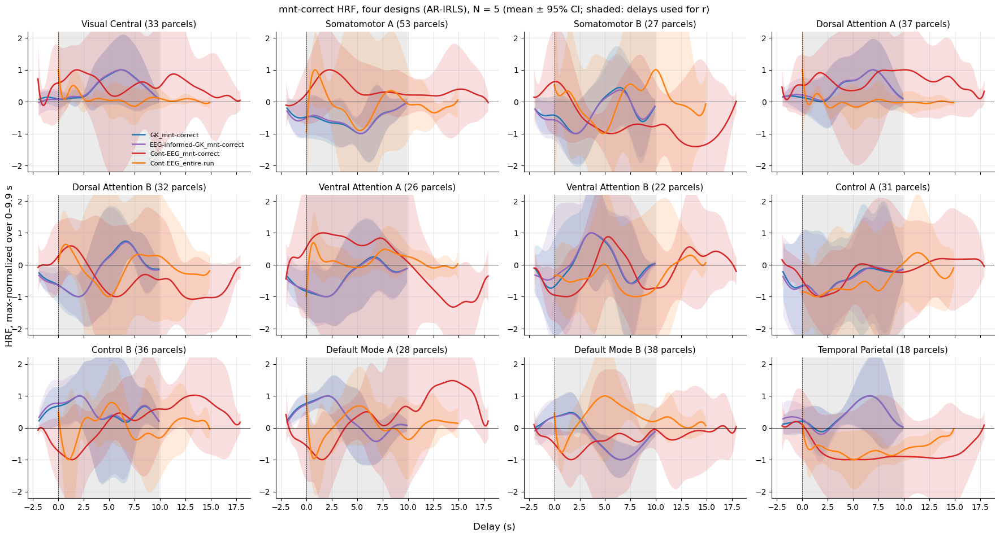

,GK_mnt-correct vs EEG-informed-GK_mnt-correct,GK_mnt-correct vs Cont-EEG_mnt-correct,GK_mnt-correct vs Cont-EEG_entire-run,EEG-informed-GK_mnt-correct vs Cont-EEG_mnt-correct,EEG-informed-GK_mnt-correct vs Cont-EEG_entire-run,Cont-EEG_mnt-correct vs Cont-EEG_entire-run
network,,,,,,
VisCent,1.00,-0.77,-0.63,-0.76,-0.61,0.44
SomMotA,0.99,-0.20,0.66,-0.10,0.72,0.31
SomMotB,0.99,-0.60,-0.19,-0.69,-0.18,0.31
DorsAttnA,1.00,-0.24,-0.24,-0.28,-0.22,0.24
DorsAttnB,1.00,-0.92,-0.34,-0.91,-0.34,0.64
SalVentAttnA,1.00,-0.51,0.00,-0.53,0.01,-0.00
SalVentAttnB,0.99,0.36,0.69,0.33,0.78,0.32
ContA,0.99,0.95,0.68,0.94,0.66,0.58
ContB,1.00,-0.77,-0.49,-0.78,-0.49,0.40


In [81]:
network_titles = {
    'VisCent': 'Visual Central', 'SomMotA': 'Somatomotor A', 'SomMotB': 'Somatomotor B',
    'DorsAttnA': 'Dorsal Attention A', 'DorsAttnB': 'Dorsal Attention B',
    'SalVentAttnA': 'Ventral Attention A', 'SalVentAttnB': 'Ventral Attention B',
    'ContA': 'Control A', 'ContB': 'Control B', 'DefaultA': 'Default Mode A', 'DefaultB': 'Default Mode B',
    'TempPar': 'Temporal Parietal',
}
network_order = list(network_titles)
win = (hrf_t >= r_win[0]) & (hrf_t <= r_win[1])

def net_parcels(parcels, net):
    return [p for p in parcels if p.split('_')[0] == net]

def group_net(d, net):
    h = np.stack([res4[s]['hrf'][d].loc[net_parcels(res4[s]['parcels'], net)].mean(0).values for s in subjects_4d])
    return h.mean(0), stats.sem(h, axis=0) * stats.t.ppf(0.975, len(h) - 1)

def plot_grid(curves, colors_map, fname, title, is_norm=True):
    fig, axs = plt.subplots(3, 4, figsize=(18, 9.6), sharex=True)
    rows = []
    for ax, net in zip(axs.flatten(), network_order):
        means = {}
        for lab in curves:
            mu, ci = group_net(lab, net)
            norm = np.nanmax(np.abs(mu[win])) if is_norm else 1
            ax.fill_between(hrf_t, (mu - ci) / norm, (mu + ci) / norm, color=colors_map[lab], alpha=0.15, lw=0)
            ax.plot(hrf_t, mu / norm, color=colors_map[lab], lw=1.8, label=lab)
            means[lab] = mu[win]
        rows.append({'network': net, **{f'{a} vs {b}': np.corrcoef(means[a], means[b])[0, 1]
                                        for i, a in enumerate(curves) for b in curves[i + 1:]}})
        ax.axhline(0, color='k', lw=0.5); ax.axvline(0, color='k', lw=0.5, ls='--')
        ax.axvspan(*r_win, color='0.92', zorder=0)
        ax.set_title(f'{network_titles[net]} ({len(net_parcels(res4[subjects_4d[0]]["parcels"], net))} parcels)', fontsize=11)
        if is_norm: ax.set_ylim(-2.2, 2.2)
        ax.grid(alpha=0.3); ax.spines[['top', 'right']].set_visible(False)
    axs[0, 0].legend(fontsize=8, frameon=False, loc='lower right')
    fig.supxlabel('Delay (s)'); fig.supylabel('HRF, max-normalized over 0–9.9 s' if is_norm else f'{select_chromo} (M)')
    fig.suptitle(f'{title}, N = {len(subjects_4d)} (mean ± 95% CI; shaded: delays used for r)')
    fig.tight_layout()
    fig.savefig(os.path.join(fig_dir_4d, fname), dpi=150)
    plt.show()
    return pd.DataFrame(rows).set_index('network')

net_r = plot_grid(dnames, d_colors, 'group_hrf_12_networks_norm.png', 'mnt-correct HRF, four designs (AR-IRLS)')
pair_cols = list(net_r.columns)
net_r.loc['median'] = net_r.median()
display(net_r.style.format('{:.2f}').background_gradient(cmap='RdBu_r', vmin=-1, vmax=1)
        .set_caption('r between group-mean network HRFs (0–9.9 s)'))

### 5c. Shape agreement at the parcel level
For each subject and parcel, `r` is computed between two designs' HRFs over 0–9.9 s. Left: the median over parcels, then over subjects. Right: the per-subject medians for each pair.

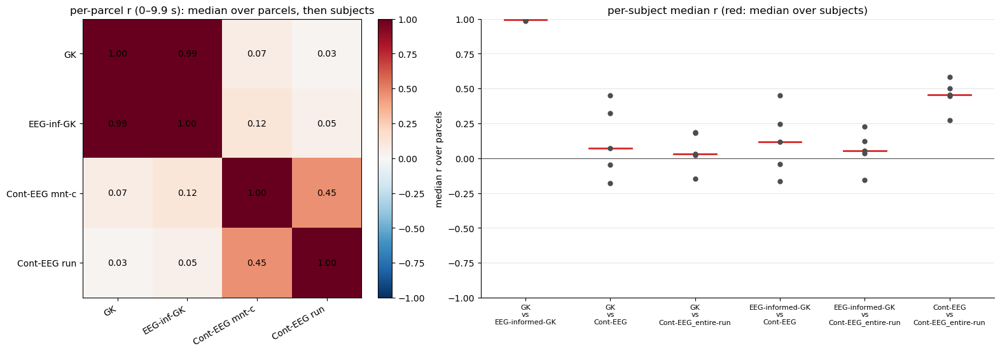

In [82]:
def parcel_r(s, a, b):
    ps = res4[s]['parcels']
    x, y = res4[s]['hrf'][a].loc[ps].values[:, win], res4[s]['hrf'][b].loc[ps].values[:, win]
    x = x - x.mean(1, keepdims=True); y = y - y.mean(1, keepdims=True)
    return (x * y).sum(1) / np.sqrt((x ** 2).sum(1) * (y ** 2).sum(1))

n = len(dnames)
mat = np.eye(n)
subj_med = {}
for i in range(n):
    for j in range(i + 1, n):
        med = [np.median(parcel_r(s, dnames[i], dnames[j])) for s in subjects_4d]
        subj_med[f'{dnames[i]} vs {dnames[j]}'] = med
        mat[i, j] = mat[j, i] = np.median(med)

fig, axs = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={'width_ratios': [1, 1.6]})
im = axs[0].imshow(mat, cmap='RdBu_r', vmin=-1, vmax=1)
for i in range(n):
    for j in range(n):
        axs[0].text(j, i, f'{mat[i, j]:.2f}', ha='center', va='center', fontsize=10)
short = ['GK', 'EEG-inf-GK', 'Cont-EEG mnt-c', 'Cont-EEG run']
axs[0].set_xticks(range(n), short, rotation=30, ha='right'); axs[0].set_yticks(range(n), short)
axs[0].set_title('per-parcel r (0–9.9 s): median over parcels, then subjects')
fig.colorbar(im, ax=axs[0], fraction=0.046)
sm = pd.DataFrame(subj_med, index=subjects_4d)
for k, col in enumerate(sm.columns):
    axs[1].scatter(np.full(len(sm), k), sm[col], color='0.3', s=25, zorder=3)
    axs[1].plot([k - 0.25, k + 0.25], [sm[col].median()] * 2, color='C3', lw=2)
axs[1].set_xticks(range(len(sm.columns)), [c.replace('_mnt-correct', '').replace(' vs ', '\nvs\n') for c in sm.columns], fontsize=8)
axs[1].axhline(0, color='k', lw=0.5); axs[1].set_ylabel('median r over parcels'); axs[1].set_ylim(-1, 1)
axs[1].set_title('per-subject median r (red: median over subjects)')
axs[1].grid(alpha=0.3, axis='y'); axs[1].spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(os.path.join(fig_dir_4d, 'hrf_corr_matrix.png'), dpi=150)
plt.show()

### 5d. Peak latency
The delay of the maximum of each group-mean network HRF within 0–9.9 s. A peak at the 9.9 s edge means the curve was still rising.

In [83]:
peak = pd.DataFrame({d: {net: hrf_t[win][np.nanargmax(group_net(d, net)[0][win])] for net in network_order} for d in dnames})
peak.loc['median'] = peak.median()
display(peak.style.format('{:.1f}').background_gradient(cmap='viridis', vmin=0, vmax=10)
        .set_caption('peak latency (s) of the group-mean network HRF, 0–9.9 s'))

,GK_mnt-correct,EEG-informed-GK_mnt-correct,Cont-EEG_mnt-correct,Cont-EEG_entire-run
VisCent,6.2,6.1,1.8,0.0
SomMotA,9.9,9.9,2.3,0.9
SomMotB,6.4,6.5,0.1,9.9
DorsAttnA,6.9,7.0,9.9,0.0
DorsAttnB,6.6,6.7,1.2,0.7
SalVentAttnA,6.6,6.6,1.6,0.7
SalVentAttnB,3.6,3.6,5.3,4.9
ContA,6.6,7.1,5.9,9.9
ContB,2.1,2.1,9.9,5.3
DefaultA,2.1,2.1,9.8,0.0


### 5e. How much does the ERP area contribute? (both Gaussian-kernel models, in M)
The EEG-informed trial-mean HRF splits into the **stim part** `B·β_stim` and the **ā·eeg part** `ā·B·β_eeg`, the change the mean ERP area adds. The grid is **not normalized**, so the parts can be compared directly with GK_mnt-correct. GK_mnt-correct shares `Y`, kernels and noise model with the EEG-informed fit.

The table gives, per subject (medians over parcels, 0–9.9 s):
- `r` between the EEG-informed trial-mean HRF and GK;
- the RMS ratio of the trial-mean HRF to GK;
- the share of the trial-mean HRF's RMS carried by the ā·eeg part;
- `corr(eeg, stim)`: the median correlation between each kernel's `eeg` and `stim` columns in the fit's design matrix.

If the ERP area varies little around its mean, the `eeg` columns are close to `ā ×` the `stim` columns. The fit can then trade one part against the other, and only their sum, the trial-mean HRF, is well determined.

,ā,"corr(eeg, stim)",r: trial-mean vs GK,RMS trial-mean / GK,RMS ā·eeg part / trial-mean
sub-695,1.09,0.92,0.99,1.00,1.04
sub-721,0.94,0.86,0.99,1.01,1.75
sub-723,0.63,0.72,0.99,1.01,0.57
sub-726,0.68,0.78,1.00,1.02,1.28
sub-730,0.44,0.70,1.00,1.01,0.36
median,0.68,0.78,0.99,1.01,1.04


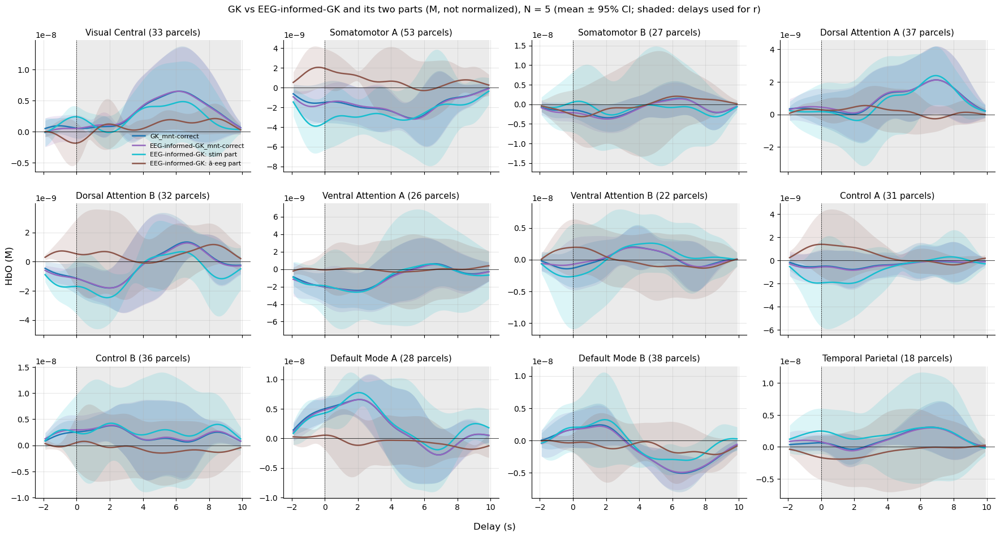

In [84]:
def rms(x):
    return np.sqrt(np.nanmean(x ** 2, axis=1))

tab = {}
for s in subjects_4d:
    ps = res4[s]['parcels']
    g = res4[s]['hrf']['GK_mnt-correct'].loc[ps].values[:, win]
    tm = res4[s]['hrf']['EEG-informed-GK_mnt-correct'].loc[ps].values[:, win]
    et = res4[s]['hrf']['EEG-informed-GK: ā·eeg part'].loc[ps].values[:, win]
    dm = load_gz(get_dm_all_path(os.path.join(D, s, f"{s}_{designs['EEG-informed-GK_mnt-correct']}"))).common.sel(chromo=select_chromo)
    regs = list(dm.regressor.values)
    e_cols = np.nan_to_num(dm.sel(regressor=[x for x in regs if x.startswith('HRF mnt-correct-eeg')]).values)
    s_cols = np.nan_to_num(dm.sel(regressor=[x for x in regs if x.startswith('HRF mnt-correct-stim')]).values)
    tab[s] = {'ā': res4[s]['a_bar'],
              'corr(eeg, stim)': np.median([np.corrcoef(e_cols[:, k], s_cols[:, k])[0, 1] for k in range(e_cols.shape[1])]),
              'r: trial-mean vs GK': np.median(parcel_r(s, 'GK_mnt-correct', 'EEG-informed-GK_mnt-correct')),
              'RMS trial-mean / GK': np.median(rms(tm) / rms(g)),
              'RMS ā·eeg part / trial-mean': np.median(rms(et) / rms(tm))}
tab = pd.DataFrame(tab).T
tab.loc['median'] = tab.median()
display(tab.style.format('{:.2f}').set_caption('GK_mnt-correct vs EEG-informed-GK (per parcel, 0–10 s)'))
gk_curves = ['GK_mnt-correct', 'EEG-informed-GK_mnt-correct', 'EEG-informed-GK: stim part', 'EEG-informed-GK: ā·eeg part']
gk_colors = dict(zip(gk_curves, [d_colors['GK_mnt-correct'], d_colors['EEG-informed-GK_mnt-correct'], '#17becf', '#8c564b']))
_ = plot_grid(gk_curves, gk_colors, 'group_hrf_12_networks_GK_vs_EEG-informed_parts.png',
              'GK vs EEG-informed-GK and its two parts (M, not normalized)', is_norm=False)

### 5f. Observations
_Filled in from the outputs above (N = 5, sub-670 excluded); update if the fits change._

1. **The ERP area adds nothing detectable to the event-locked HRF.**
   - The EEG-informed trial-mean HRF is essentially the plain GK HRF: per-parcel r = 0.99 and RMS ratio 1.01 in every subject. The group network curves overlap (5b), and the peak latencies are the same (median 6.5 s for both).
   - The test on β_eeg is at chance (median 5% of parcels with p < 0.05, range 3–18%). The plain GK HRF passes it in 46% of parcels.
2. **The two parts of the EEG-informed fit are poorly identified.**
   - Within each subject, the `eeg` and `stim` columns correlate at r = 0.70–0.92, because the ERP area varies little around its mean.
   - The ā·eeg part can be as large as the whole HRF (RMS share 0.36–1.75), while the stim part cancels it. Only their sum is stable.
   - Per-trial HRFs from this model (as in `vis_hrf.py`'s ERP-image) are therefore dominated by this trade-off. They should not be read as an ERP-area effect.
3. **The continuous-EEG HRFs are a different object from the event-locked HRF.**
   - Per-parcel r is 0.03–0.12 between either Gaussian-kernel model and either continuous-EEG model. At the network level the shapes are mostly anti-correlated: median r −0.56 (mnt-correct) and −0.29 (entire run). The exceptions are ContA (r = 0.95 with Cont-EEG_mnt-correct) and SalVentAttnB.
   - Peaks: the Gaussian-kernel HRFs peak at ~6–7 s in visual, attention and somatomotor networks, and at ~2 s in ContB/Default. The continuous-EEG HRFs peak either right after 0 s (entire run: median 0.8 s) or at the window edge.
4. **The two continuous-EEG designs only partly agree** with each other (per-parcel r = 0.45; network median 0.42), even though both weight Cz EEG. Restricting the EEG to mnt-correct trials changes the estimate substantially.
5. **Significance does not mean a hemodynamic response.** The entire-run continuous-EEG model has the highest fraction of significant parcels (median 83%), yet its HRF peaks within ~1 s of the EEG and generalizes to no held-out run (§4 Stage 6). Like the fixAR-IRLS F-tests, these AR-IRLS F-tests are likely anti-conservative for a slowly varying regressor.
6. **Caveats.**
   - N = 5.
   - `Cont-EEG_mnt-correct` (`city`) predates the alignment fix and uses its own `Y` (0.01 Hz highpass). Rerunning it on the shared `Y_all` would make all four designs differ only in the design.


### 5g. Single-parcel example: DorsAttnB_PostC_2_RH (the parcel of the Bayesian model, §4 Stage 9)
HRFs of one right postcentral dorsal-attention parcel from three scripts:
1. `run_model_EEG_inform_parcel_based.py`: `onlyStim` and `onlyEEG`.
2. All three models of `run_model_cont_EEG_city_mnt.py`, mnt-correct block.
3. All three models of the entire-run continuous-EEG design. AR-IRLS comes from `run_model_cont_EEG_fNIRS.py`; fixAR-IRLS and AR-iRRR come from `run_model_cont_EEG_fNIRS_fixAR-IRLS.py` and `run_model_cont_EEG_fNIRS_AR-iRRR.py`, which refit its `Y_all` and design.

How the figures are drawn:
- Each panel shows thin lines for subjects, sub-723 in black (the Bayesian subject), and the group mean ± t-based 95% CI.
- sub-670 is excluded (duplicated runs in the shared `Y_all`).
- No baseline correction.
- `onlyEEG` regressors are kernels scaled by each trial's Cz ERP area, so its HRF is shown as the trial mean `ā·B·β` in M, the same unit as `onlyStim`.

Provenance:
- `onlyEEG` was first fit on 2026-11-03 (unchanged script, `model_type='onlyEEG'`).
- The figures were made with a one-off plotting script that is not in the repo.
- The `city` outputs and the entire-run fixAR-IRLS / AR-iRRR fits predate the EEG-alignment fix (`e99d06d`); the entire-run AR-IRLS fit was redone after it.

**What the figures show**
- **The event-locked designs give a plausible HRF.** `onlyStim` and `onlyEEG` share one shape: a dip at ~2 s and a peak at ~6 s (sub-723: ~5 s). This matches the Bayesian posterior mean at this parcel.
- **The EEG-weighted designs do not.** Their curves (M/V) are negative or flat, with a wide subject spread:
  - `city` AR-IRLS / fixAR-IRLS: negative from ~3 s;
  - entire-run AR-IRLS / fixAR-IRLS: a shallow dip at ~4 s;
  - AR-iRRR: shrunk to nearly flat (`city`), or an oscillation driven by sub-723 (entire run).

**Parcel location: DorsAttnB_PostC_2_RH (right postcentral gyrus).**  
<sub>`/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/parcel_location/DorsAttnB_PostC_2_RH_location.png`</sub>

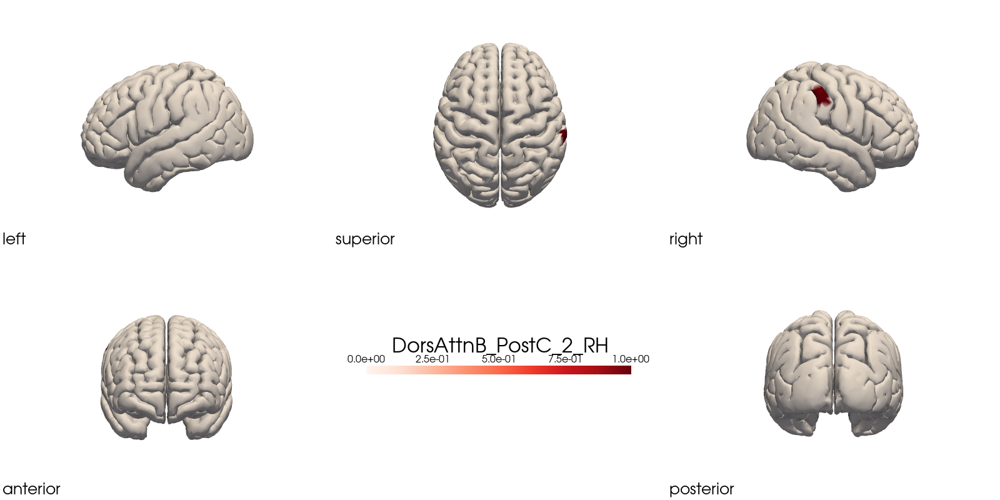

**1. run_model_EEG_inform_parcel_based.py: onlyStim vs onlyEEG (trial mean), mnt-correct, AR-IRLS (M).**  
<sub>`/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/HRF_surf/group/parcel_DorsAttnB_PostC_2_RH/1_EEG_inform_parcel_onlyStim_onlyEEG.png`</sub>

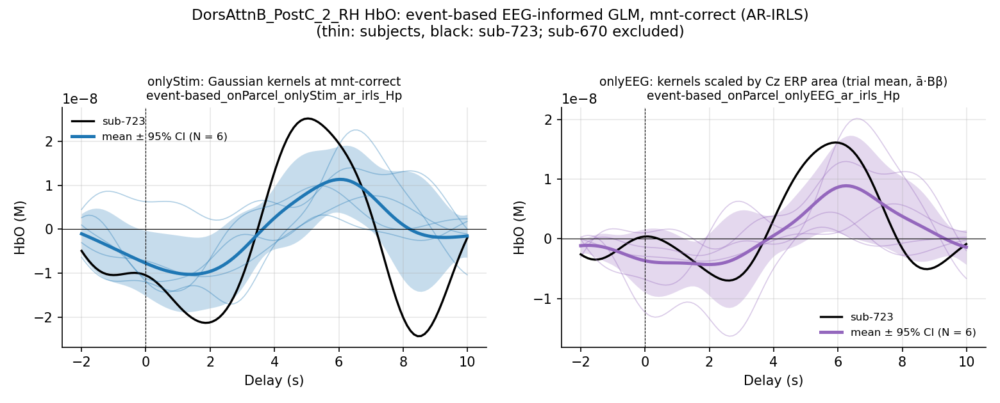

**2. run_model_cont_EEG_city_mnt.py: AR-IRLS, fixAR-IRLS, AR-iRRR; Cz EEG within mnt-correct trials (M/V, pre-alignment-fix).**  
<sub>`/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/HRF_surf/group/parcel_DorsAttnB_PostC_2_RH/2_cont_EEG_city_mnt_mnt-correct.png`</sub>

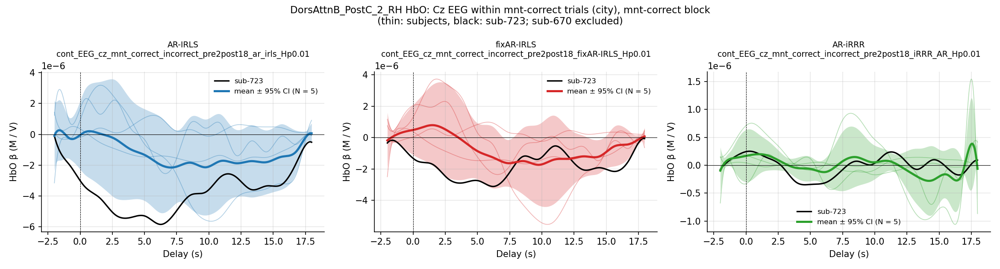

**3. Continuous Cz EEG over the entire run: AR-IRLS (run_model_cont_EEG_fNIRS.py), fixAR-IRLS, AR-iRRR (M/V).**  
<sub>`/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/HRF_surf/group/parcel_DorsAttnB_PostC_2_RH/3_cont_EEG_fNIRS_entire-run.png`</sub>

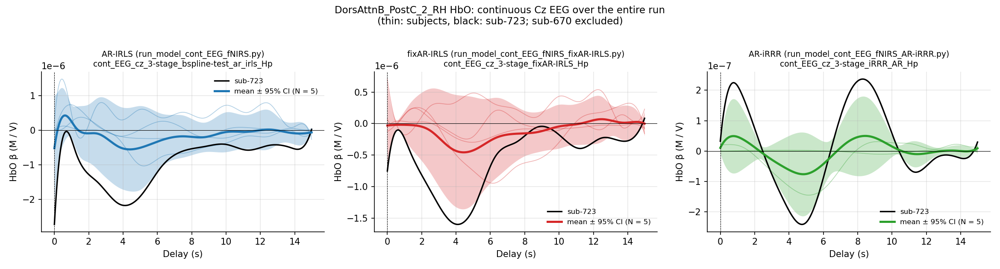

In [85]:
P4 = os.path.join(G, 'parcel_DorsAttnB_PostC_2_RH')
show([
    ('Parcel location: DorsAttnB_PostC_2_RH (right postcentral gyrus).',
     os.path.join(D, 'parcel_location/DorsAttnB_PostC_2_RH_location.png')),
    ('1. run_model_EEG_inform_parcel_based.py: onlyStim vs onlyEEG (trial mean), mnt-correct, AR-IRLS (M).',
     os.path.join(P4, '1_EEG_inform_parcel_onlyStim_onlyEEG.png')),
    ('2. run_model_cont_EEG_city_mnt.py: AR-IRLS, fixAR-IRLS, AR-iRRR; Cz EEG within mnt-correct trials (M/V, pre-alignment-fix).',
     os.path.join(P4, '2_cont_EEG_city_mnt_mnt-correct.png')),
    ('3. Continuous Cz EEG over the entire run: AR-IRLS (run_model_cont_EEG_fNIRS.py), fixAR-IRLS, AR-iRRR (M/V).',
     os.path.join(P4, '3_cont_EEG_fNIRS_entire-run.png')),
])

## 6. Conclusion: what modeling the HRF with EEG and fNIRS has shown

**Goal.** The aim was to use simultaneous scalp EEG to explain or inform the fNIRS HbO response in gradCPT, in two ways:
- **trial-wise**, with single-trial Cz EEG features (ERP area, alpha power) modulating an event-locked HRF;
- **continuously**, with the Cz EEG as a delayed regressor, which gives an EEG→HbO transfer function.

Both were tried in channel and parcel space, with several noise models (AR-IRLS, fixAR-IRLS), a low-rank multi-parcel estimator (AR-iRRR) and a Bayesian joint HRF + AR model.

### 6.1 Findings

**1. There is an event-locked HbO response to correct mountain withholds, and it does not need EEG.**
- In ContA it peaks at ~4.5–6.5 s and dips at ~8 s (§4 Stage 7). Prefrontal control, default and ventral-attention parcels are the most significant, several of them in every subject (§4 Stage 8). The single-parcel example in §5g shows the same shape.
- The shape is robust to the noise model (AR-IRLS vs fixAR-IRLS r = 0.87–0.91) and to pipeline choices (r = 0.91–0.98).
- It is still weak relative to the noise at the single-subject level. Trained on one run, it does not improve prediction of the other two (best held-out iRRR rank 0 in 14 of 20 subjects).

**2. EEG adds no detectable, generalizable information about HbO.**
- **Trial-wise:** scaling the event regressors by the single-trial Cz ERP area leaves the HRF unchanged (r = 0.99, amplitude ratio 1.01). The ERP-area term is at chance (median 5% of parcels with p < 0.05). Its regressor correlates 0.70–0.92 with the plain event regressor, so the design has little leverage to detect a modulation (§5).
- **Continuous:**
  - The Cz-EEG regressors explain < 2% of the whitened HbO variance in-sample and ≈ 0 out-of-sample. Cross-validated λ₁ selects rank 0 for half the subjects (§4 Stages 5–6).
  - The resulting "HRFs" differ from the event-locked HRF (per-parcel r = 0.03–0.12, network-level shapes mostly anti-correlated). They often peak within 0–2 s of the EEG, which is too early for a hemodynamic response, and they vary across subjects.
  - Restricting the EEG to mnt-correct trials or using the whole run gives only partly similar estimates (r ≈ 0.45) (§5).
- **Significance without generalization:** large fractions of parcels pass F-tests in the continuous-EEG models (68–83%), yet those models fail on held-out runs. Parametric F-tests with a slowly varying regressor and a shared whitening kernel look anti-conservative here.

**3. Estimator choices change amplitude, not conclusions.**
- fixAR-IRLS HRFs are ~0.8× the AR-IRLS amplitude, with nearly the same shape.
- AR-iRRR shrinks them to ~0.2–0.6× and smooths them.
- The low-rank components differ between subjects, so there is **no single shared EEG→HbO HRF shape** across subjects.

**4. The Bayesian joint model points the same way.** At DorsAttnB_PostC_2_RH (sub-723, one run), propagating noise-model uncertainty gives an event-HRF posterior mean of the expected shape. Its 95% credible band contains 0 at nearly all lags.

### 6.2 Interpretation (hypotheses, not tested here)
- **Spatial mismatch:** a single scalp channel (Cz) is a coarse proxy for the local activity that drives each cortical parcel's hemodynamics.
- **Little trial-to-trial variability:** the ERP area summarizes one component at one site and varies little around its mean. That gives the trial-wise model almost no leverage.
- **Shared non-neural signals:** broadband continuous EEG is dominated by noise, artifacts and slow drifts. Shared systemic or motion components could explain near-zero-lag "coupling" better than neurovascular coupling.
- **Power:** the EEG analyses have N = 5–6 subjects and ~80–125 mnt-correct trials each, against very small effects.

### 6.3 Implications and recommendations
1. **Treat the event-locked mnt-correct HRF as the primary fNIRS result.** So far, EEG-informed and EEG-weighted HRFs are null results.
2. **Require out-of-sample evidence** (held-out runs, permutation or phase-randomized-EEG nulls) before claiming EEG–fNIRS coupling. Parametric F-tests alone are not enough here.
3. **If the EEG question is pursued further:**
   - centre trial-wise features per subject (`a_i − ā`);
   - use features with physiological rationale and more trial variability (pre-stimulus posterior alpha, frontal theta, single-trial P3 amplitude);
   - use multichannel or source-level EEG matched to parcels;
   - pool across subjects with a hierarchical Bayesian model;
   - add subjects.
4. **Finish the open fixes first** (§8): rerun `city` after the alignment fix on the shared `Y_all`, fix the beta–basis pairing in `vis_hrf.py`, and rebuild sub-670's `Y_all`. These are unlikely to reverse the conclusions, but they remove known confounds.

## 7. Methodological lessons

| Issue | Consequence | Fix / status |
|---|---|---|
| Own AR-IRLS ≠ Cedalion | HRFs differed from the lab's | Matched pmax = 30 and Tukey c = 4.685 (`4c8bd13`) |
| Robust-fit F-test | Full-model weighted RSS can exceed the reduced model's | Documented in `proof_RLM_RSS_full_smaller_than_reduced.py`; interpret F-tests with care |
| Per-parcel AR filter on Y only | Removed the low-frequency EEG → iRRR failed | Spectral whitening applied to Y and X (`12d3a51`) |
| Unscaled Y (~1e-8 M) | `RLM` stops after 2 iterations; λ₁ = 1 kills iRRR | Divide by `Y_scale` (`89c13ab`) |
| Shared whitening kernel | F-tests likely anti-conservative (68% of parcels significant) | Open; needs permutation or held-out checks |
| `mne.resample` of EEG to the fNIRS rate | EEG→fNIRS misalignment | Lowpass to the fNIRS Nyquist and sample at the exact times (`e99d06d`); rerun older outputs |
| Duplicated runs in sub-670's `Y_all` | Biased fits | Skipped by the network scripts; the shared `Y_all` should be rebuilt |
| Overlapping Gaussian kernels | Basis condition number ~5000; alternating ± coefficient patterns dominate an SVD of C | Analyse H = basis·C; a better-conditioned basis would need a refit |
| `vis_hrf.py` builds per-trial HRFs as `concat([basis, basis·area])`, but `estimate_HRF_from_beta` pairs betas by position and the betas are ordered `[eeg, stim]` | The plain and ERP-area parts are swapped (`B·β_eeg + a_i·B·β_stim`) | Open: concatenate as `[basis·area, basis]` (or select betas by name). §5 uses the correct pairing |
| EEG-informed design: `eeg` columns ≈ ā × `stim` columns (r = 0.70–0.92) | The two parts trade off; only their sum is identified | Center the ERP area per subject (`a_i − ā`) so β_eeg is the modulation and β_stim the mean HRF |
| Highpass and kernel settings changed mid-study | Stage 7 write-up used 0.02 Hz / 12 kernels; the script now uses 0.01 Hz / 20 kernels | Note when comparing results |

## 8. Open items and suggested next steps

1. **Rerun `city`** (`run_model_cont_EEG_city_mnt.py`) after the alignment fix, then write §16 of `summary_run_model_cont_EEG_city_mnt.ipynb`.
2. **Explain the 0–2 s peak** of the EEG-weighted HRFs. Is it a residual alignment or causality issue (check the negative delays), or EEG artifact shared with fNIRS (e.g., motion or systemic)?
3. **Calibrate the F-tests.** Use a permutation or phase-randomized-EEG null for fixAR-IRLS. With R² < 2% and no generalization, the high significant fractions are suspicious.
4. **Rebuild sub-670's shared `Y_all`** (duplicated runs) and recheck the outlier subjects sub-751 and sub-719.
5. **Bayesian model:**
   - save the v2 posteriors and run diagnostics (R̂, ESS, divergences);
   - fit all three runs;
   - compare against fixAR-IRLS on the same parcel;
   - scale up: more parcels, a hierarchical prior across subjects and parcels, and an EEG-weighted design;
   - to use `az.loo` and posterior predictive checks, replace the `pm.Potential` likelihood with `pm.CustomDist`.
6. **EEG-informed GLM:** refit with the per-subject-centered ERP area (see §7), fix the beta–basis pairing in `vis_hrf.py`, and rerun `city` on the shared `Y_all` so that the §5 comparison varies only the design.
7. Given the null generalization results, consider whether the EEG→HbO question should move to other EEG features (frontal theta, posterior alpha, ERP components) or to trial-level prediction instead of continuous regression.

## 9. Where to find things

| What | Where |
|---|---|
| Script-by-script logic flow and full figure index | [README.md](README.md) |
| Shared paths, configs, subject exclusion | [params_setting.py](params_setting.py) |
| Design matrices, fitters, HRF reconstruction, EEG features | [model.py](model.py) |
| Stage 5 write-up | [summary_Hp_fixAR-IRLS_iRRR_AR.ipynb](summary_Hp_fixAR-IRLS_iRRR_AR.ipynb) |
| Stage 6 write-up | [summary_cmp_fixAR-IRLS_AR-iRRR_single-subj.ipynb](summary_cmp_fixAR-IRLS_AR-iRRR_single-subj.ipynb) |
| Stage 7 write-up | [summary_cmp_AR-IRLS_fixAR-IRLS_AR-iRRR.ipynb](summary_cmp_AR-IRLS_fixAR-IRLS_AR-iRRR.ipynb) |
| Stage 8 write-ups | [summary_AR-iRRR_fixAR-IRLS_network-based.ipynb](summary_AR-iRRR_fixAR-IRLS_network-based.ipynb), [summary_run_model_cont_EEG_city_mnt.ipynb](summary_run_model_cont_EEG_city_mnt.ipynb) |
| Stage 9 | [Bayesian model/](Bayesian%20model/) |
| Outputs | `/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg` (`<subject>/betas`, `stats`, `Y_all`, `bayes`; `HRF_surf/…` figures) |
| iRRR solver (external) | `/projectnb/stephenlab/cchang1/iRRR_python` |